# Transfer learning 
- Ideea e sa luam un model antrenat pe un task si sa il utilizam pe alt task
- vrem sa stim daca modelul stie sa recunoasca autorul si din summary 

Antrenare originală: <br>
text lung → BERT → projection head → triplet loss <br>
(modelul a învățat reprezentări stilistice)


Transfer learning:<br>
summary scurt → BERT (același, cu weights învățate) → classifier nou → autor

Nu există o funcție specială de transfer learning în PyTorch — e pur și simplu:

Încarci modelul salvat <br>
Extragi partea care te interesează (BERT-ul) <br>
Adaugi un capăt nou (classifier) <br>
Alegi ce înghețezi și ce antrenezi <br>
 
Atentie! Rezumatele trebuie sa fie tot in romana

Din ce vad ele sunt destul de similare cu textele originale deci , nu mai e necesar neaparat sa dai unfreeze la ultimele x straturi si sa le antrenezi pe alea, trebuie doar reantrenat clasificatorul 

In [2]:
import pandas as pd

In [3]:
train_df = pd.read_csv("final_stilo/top20_ro_train.csv")

In [4]:
train_df.head()

,text,summary,title,keywords,dialect,topics,url,author,stylo_word_count,stylo_char_count,...,adv_flesch_ro,adv_gunning_fog,adv_mttr,adv_mtld,adv_unique_bigram_rate,adv_unique_trigram_rate,adv_diacritic_ratio,adv_suffix_rate,adv_uppercase_words_rate,adv_ellipsis_rate
0,Andreea Tobias„Creșterea natalității este o pr...,"Ministrul Familiei, Gabriela Firea, anunță un ...",NaN,"crestere,natalitate,firea,copii,tva,masuri,famil",0.0,politic,https://www.mediafax.ro/social/masuri-anuntate...,Andreea Tobias,596,4112,...,33.619985,29.083371,0.960465,104.717805,0.897479,0.956229,0.038181,0.038591,0.003356,0.0
1,Se presupune că recruții ruși sunt trimiși la ...,Se presupune că recruții ruși sunt trimiși la ...,"Rușii sunt trimiși la război cu „arme vechi, r...",NaN,0.0,guvern,https://alephnews.ro/guvern/rusii-sunt-trimisi...,Alina Manaila,194,1156,...,62.827099,21.807364,0.961957,116.735668,0.917098,0.958333,0.044118,0.015464,0.015464,0.0
2,Andreea TobiasEvgheni Prigojin a declarat că t...,"Luptele din jurul orașului Bahmut, din estul U...",NaN,"bahmut,zelenski,rusia,ucrain",0.0,externe,https://www.mediafax.ro/externe/zelenski-le-mu...,Andreea Tobias,362,2226,...,29.439937,32.950908,0.970435,161.995794,0.936288,0.988889,0.043127,0.024862,0.002762,0.0
3,"Andreea TobiasSâmbătă, la Punctul de Trecere a...",Medicamente contrafăcute în valoare totală de ...,NaN,"medicamente,contrafacute,nadlac,politisti de f...",0.0,social,https://www.mediafax.ro/social/medicamente-con...,Andreea Tobias,125,798,...,30.353333,31.066667,0.965455,114.443354,0.951613,0.975610,0.056391,0.024000,0.008000,0.0
4,Andreea TobiasVicepreședintele executiv va ave...,Vicepreședintele executiv pentru Pactul verde ...,NaN,"frans timmermans,romania,comisia europeana,viz...",0.0,politic,https://www.mediafax.ro/politic/vicepresedinte...,Andreea Tobias,128,936,...,0.000000,53.201018,0.952941,153.600000,0.968504,0.976190,0.053419,0.039062,0.000000,0.0


In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModel
from transformers import get_linear_schedule_with_warmup
from torch.optim import AdamW
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix
import numpy as np
import pandas as pd
import re
import unicodedata
import os
import json
import random
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [2]:
BERT_MODEL  = "dumitrescustefan/bert-base-romanian-cased-v1"
MAX_LEN     = 512
OUTPUT_DIR  = 'outputs_transfer'
device      = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
tokenizer   = AutoTokenizer.from_pretrained(BERT_MODEL)

print(f"Device: {device}")

Device: cuda


Our friends our functions

In [3]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark     = False

set_seed(42)

def normalize_romanian(text):
    return text.replace("ţ", "ț").replace("ş", "ș") \
               .replace("Ţ", "Ț").replace("Ş", "Ș")

def clean_text(text):
    if not isinstance(text, str):
        return ""
    text = unicodedata.normalize("NFC", text)
    text = normalize_romanian(text)
    text = ''.join(c for c in text if not unicodedata.combining(c))
    text = text.replace("„", '"').replace("\u201d", '"')
    text = text.replace("\u2019", "'")
    text = ''.join(c for c in text if unicodedata.category(c)[0] != 'C')
    text = text.replace("\n", " ").replace("\t", " ")
    text = text.replace('""', '"')
    text = re.sub(r"\s+", " ", text)
    return text.strip()

Redeclaram clasa de TripletBert ca sa putem declara modelul

In [4]:
class TripleBERTAuthorship(nn.Module):
    def __init__(self, num_authors, projection_dim=128, dropout=0.2):
        super().__init__()
        self.bert           = AutoModel.from_pretrained(BERT_MODEL)
        self.dropout        = nn.Dropout(dropout)
        self.classifier     = nn.Linear(768, num_authors)
        self.projection_head = nn.Sequential(
            nn.Linear(768, projection_dim)
        )
    
    def forward(self, input_ids, attention_mask):
        bert_out  = self.bert(input_ids=input_ids,
                               attention_mask=attention_mask)
        cls       = bert_out.last_hidden_state[:, 0, :]
        cls       = self.dropout(cls)
        logits    = self.classifier(cls)
        projection = self.projection_head(cls)
        projection = F.normalize(projection, p=2, dim=1)
        return logits, projection
    
    def get_embedding(self, input_ids, attention_mask):
        with torch.no_grad():
            bert_out   = self.bert(input_ids=input_ids,
                                    attention_mask=attention_mask)
            cls        = bert_out.last_hidden_state[:, 0, :]
            projection = self.projection_head(cls)
            projection = F.normalize(projection, p=2, dim=1)
        return projection

Peste modelul vechi (backbone-ul) adaugam un classifier care asta e cel care va clasifica
Practic urmam a doua strategie conform documentatiei pythorch:
These two major transfer learning scenarios look as follows:

    Finetuning the ConvNet: Instead of random initialization, we initialize the network with a pretrained network, like the one that is trained on imagenet 1000 dataset. Rest of the training looks as usual.

    ConvNet as fixed feature extractor: Here, we will freeze the weights for all of the network except that of the final fully connected layer. This last fully connected layer is replaced with a new one with random weights and only this layer is trained.


Adica fixed featrue extractor, freeze si antrenare doar pe clasificator.

In [6]:
class TransferClassifier(nn.Module):
    """
    Incarca BERT-ul din modelul Triplet antrenat
    si adauga un classifier nou pentru summary.
    
    BERT-ul e frozen — nu se modifica weights-urile lui.
    Doar Linear(768, num_authors) se antreneaza.
    """
    def __init__(self, pretrained_path, num_authors,
                 dropout=0.2):
        super().__init__()
        
        # incarcam modelul triplet ca sa extragem BERT-ul
        checkpoint  = torch.load(pretrained_path, map_location='cpu')
        model_vechi = TripleBERTAuthorship(num_authors=num_authors)
        model_vechi.load_state_dict(checkpoint)
        
        # extragem BERT cu weights pre-antrenate
        self.bert = model_vechi.bert
        del model_vechi  # elibereaza memoria
        
        # inghetam BERT — nu se modifica
        for param in self.bert.parameters():
            param.requires_grad = False
        print(f"BERT frozen — parametri antrenabili: classifier only")
        
        # classifier nou pentru summary
        self.dropout    = nn.Dropout(dropout)
        self.classifier = nn.Linear(768, num_authors)
    
    def forward(self, input_ids, attention_mask):
        # BERT nu calculeaza gradienti (e frozen)
        with torch.no_grad():
            bert_out = self.bert(
                input_ids=input_ids,
                attention_mask=attention_mask
            )
        cls    = bert_out.last_hidden_state[:, 0, :]
        cls    = self.dropout(cls)
        logits = self.classifier(cls)
        return logits

DEclaram noua structura de dataset (summary) ma rog nu se schimba mare lucru dar pt consistenta facem asa

In [7]:
class SummaryDataset(Dataset):
    def __init__(self, texts, labels, tokenizer,
                 max_length=MAX_LEN):
        self.tokenizer  = tokenizer
        self.max_length = max_length
        self.texts      = [clean_text(t) for t in texts]
        self.labels     = labels
    
    def __len__(self):
        return len(self.texts)
    
    def __getitem__(self, idx):
        encoded = self.tokenizer(
            self.texts[idx],
            max_length=self.max_length,
            truncation=True,
            padding='max_length',
            return_tensors='pt'
        )
        return {
            'input_ids':      encoded['input_ids'].squeeze(0),
            'attention_mask': encoded['attention_mask'].squeeze(0),
            'label':          torch.tensor(self.labels[idx], dtype=torch.long)
        }

Train

In [8]:
def train_epoch_transfer(model, loader, optimizer,
                          scheduler, device):
    model.train()
    criterion  = nn.CrossEntropyLoss()
    total_loss = 0.0
    all_preds, all_labels = [], []
    
    for batch in loader:
        ids    = batch['input_ids'].to(device)
        mask   = batch['attention_mask'].to(device)
        labels = batch['label'].to(device)
        
        optimizer.zero_grad(set_to_none=True)
        logits = model(ids, mask)
        loss   = criterion(logits, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(
            model.parameters(), 1.0
        )
        optimizer.step()
        scheduler.step()
        
        total_loss += loss.item()
        preds = torch.argmax(logits, dim=-1)
        all_preds .extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
    
    f1  = f1_score(all_labels, all_preds, average='macro')
    acc = accuracy_score(all_labels, all_preds)
    return total_loss / len(loader), f1, acc


def eval_epoch_transfer(model, loader, device):
    model.eval()
    criterion  = nn.CrossEntropyLoss()
    total_loss = 0.0
    all_preds, all_labels = [], []
    
    with torch.no_grad():
        for batch in loader:
            ids    = batch['input_ids'].to(device)
            mask   = batch['attention_mask'].to(device)
            labels = batch['label'].to(device)
            
            logits = model(ids, mask)
            loss   = criterion(logits, labels)
            
            total_loss += loss.item()
            preds = torch.argmax(logits, dim=-1)
            all_preds .extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    
    f1  = f1_score(all_labels, all_preds, average='macro')
    acc = accuracy_score(all_labels, all_preds)
    return total_loss / len(loader), f1, acc

Fcaem o functie wrapper

In [9]:
def prepare_transfer_data(train_df, val_df, test_df,
                           batch_size=16):
    """
    Construieste dataset-uri si loadere pentru summary.
    """
    le = LabelEncoder()
    le.fit(train_df['author'])
    
    y_train = le.transform(train_df['author'])
    y_val   = le.transform(val_df['author'])
    y_test  = le.transform(test_df['author'])
    
    train_ds = SummaryDataset(
        train_df['summary'].tolist(), y_train, tokenizer
    )
    val_ds   = SummaryDataset(
        val_df['summary'].tolist(),   y_val,   tokenizer
    )
    test_ds  = SummaryDataset(
        test_df['summary'].tolist(),  y_test,  tokenizer
    )
    
    train_loader = DataLoader(train_ds, batch_size=batch_size,
                               shuffle=True)
    val_loader   = DataLoader(val_ds,   batch_size=batch_size,
                               shuffle=False)
    test_loader  = DataLoader(test_ds,  batch_size=batch_size,
                               shuffle=False)
    
    print(f"Autori: {len(le.classes_)}")
    print(f"Train: {len(train_ds)} | Val: {len(val_ds)} | Test: {len(test_ds)}")
    
    return le, y_train, y_val, y_test, \
           train_loader, val_loader, test_loader

In [10]:
def train_transfer(model, train_loader, val_loader,
                   dataset_name, epochs=10, lr=1e-3,
                   seed=42):
    """
    Antreneaza TransferClassifier.
    Returneaza modelul best + history.
    """
    set_seed(seed)
    
    out_dir = os.path.join(OUTPUT_DIR, dataset_name)
    os.makedirs(out_dir, exist_ok=True)
    
    model_path = os.path.join(
        out_dir, f'transfer_frozen_{dataset_name}.pt'
    )
    
    # doar classifier se antreneaza
    optimizer = AdamW(
        model.classifier.parameters(), lr=lr
    )
    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps=len(train_loader) // 10,
        num_training_steps=len(train_loader) * epochs
    )
    
    best_f1 = 0
    
    train_losses, val_losses = [], []
    train_f1s,   val_f1s    = [], []
    train_accs,  val_accs   = [], []
    
    for epoch in range(epochs):
        train_loss, train_f1, train_acc = train_epoch_transfer(
            model, train_loader, optimizer, scheduler, device
        )
        val_loss, val_f1, val_acc = eval_epoch_transfer(
            model, val_loader, device
        )
        
        train_losses.append(train_loss)
        val_losses  .append(val_loss)
        train_f1s   .append(train_f1)
        val_f1s     .append(val_f1)
        train_accs  .append(train_acc)
        val_accs    .append(val_acc)
        
        print(f"Epoch {epoch+1}/{epochs} — "
              f"Train F1: {train_f1:.4f} | "
              f"Val F1: {val_f1:.4f} | "
              f"Val Acc: {val_acc:.4f}")
        
        if val_f1 > best_f1:
            best_f1 = val_f1
            torch.save(model.state_dict(), model_path)
            print(f"  Salvat (F1={val_f1:.4f})")
    
    print(f"\nBest Val F1: {best_f1:.4f}")
    
    # incarca best
    model.load_state_dict(
        torch.load(model_path, map_location=device)
    )
    
    history = {
        'train_losses': train_losses,
        'val_losses':   val_losses,
        'train_f1s':    train_f1s,
        'val_f1s':      val_f1s,
        'train_accs':   train_accs,
        'val_accs':     val_accs,
        'best_val_f1':  best_f1
    }
    
    return model, model_path, history


Grafice

In [11]:
def plot_transfer_curves(history, dataset_name="",
                          save_path=None):
    """
    Curbe de loss, F1 si accuracy pe train si val.
    """
    epochs_range = range(1, len(history['train_losses']) + 1)
    
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle(
        f'Transfer Learning — {dataset_name}',
        fontsize=14, y=1.02
    )
    
    # Loss
    ax = axes[0]
    ax.plot(epochs_range, history['train_losses'],
            label='Train', marker='o', color='steelblue')
    ax.plot(epochs_range, history['val_losses'],
            label='Val',   marker='o', color='coral')
    ax.set_title('Loss')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Loss')
    ax.legend()
    ax.grid(True)
    
    # F1
    ax = axes[1]
    ax.plot(epochs_range, history['train_f1s'],
            label='Train', marker='o', color='blue')
    ax.plot(epochs_range, history['val_f1s'],
            label='Val',   marker='o', color='orange')
    ax.set_title('Macro F1')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('F1')
    ax.legend()
    ax.grid(True)
    
    # Accuracy
    ax = axes[2]
    ax.plot(epochs_range, history['train_accs'],
            label='Train', marker='o', color='purple')
    ax.plot(epochs_range, history['val_accs'],
            label='Val',   marker='o', color='green')
    ax.set_title('Accuracy')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Accuracy')
    ax.legend()
    ax.grid(True)
    
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"Salvat: {save_path}")
    plt.show()
    plt.close()


def plot_transfer_confusion_matrix(y_true, y_pred, classes,
                                    dataset_name="",
                                    save_path=None):
    n         = len(classes)
    cm_counts = confusion_matrix(y_true, y_pred)
    cm_norm   = cm_counts.astype(float) / \
                cm_counts.sum(axis=1, keepdims=True)
    
    fig_size  = max(10, n * 0.7)
    font_size = max(6, int(300 / n))
    short     = [c.split()[-1] for c in classes]
    
    fig, axes = plt.subplots(
        1, 2, figsize=(fig_size * 2 + 2, fig_size)
    )
    fig.suptitle(
        f'Confusion Matrix — Transfer {dataset_name}',
        fontsize=14
    )
    
    for ax, data, fmt, subtitle in [
        (axes[0], cm_counts, 'd',    'Counts'),
        (axes[1], cm_norm,   '.2f',  'Normalized'),
    ]:
        sns.heatmap(
            data, ax=ax,
            xticklabels=short, yticklabels=short,
            cmap='Blues', annot=True, fmt=fmt,
            annot_kws={'size': font_size}, square=True
        )
        ax.set_title(subtitle)
        ax.set_xlabel('Predicted')
        ax.set_ylabel('True')
        ax.set_xticklabels(
            ax.get_xticklabels(),
            rotation=45, ha='right', fontsize=font_size
        )
        ax.set_yticklabels(
            ax.get_yticklabels(),
            rotation=0, fontsize=font_size
        )
    
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"Salvat: {save_path}")
    plt.show()
    plt.close()


Evaluare

In [12]:
def evaluate_transfer(model, test_loader, y_test,
                       le, dataset_name,
                       model_path=None):
    """
    Incarca modelul (optional) si evalueaza pe test.
    Afiseaza classification report si confusion matrix.
    """
    out_dir = os.path.join(OUTPUT_DIR, dataset_name)
    os.makedirs(out_dir, exist_ok=True)
    
    if model_path:
        model.load_state_dict(
            torch.load(model_path, map_location=device)
        )
        print(f"Model incarcat: {model_path}")
    
    model.eval()
    all_preds = []
    
    with torch.no_grad():
        for batch in test_loader:
            ids    = batch['input_ids'].to(device)
            mask   = batch['attention_mask'].to(device)
            logits = model(ids, mask)
            preds  = torch.argmax(logits, dim=-1)
            all_preds.extend(preds.cpu().numpy())
    
    f1  = f1_score(y_test, all_preds, average='macro')
    acc = accuracy_score(y_test, all_preds)
    
    print(f"\n=== Rezultate Test — {dataset_name} ===")
    print(f"F1 Macro:  {f1:.4f}")
    print(f"Accuracy:  {acc:.4f}")
    print(classification_report(
        y_test, all_preds,
        target_names=le.classes_,
        zero_division=0
    ))
    
    plot_transfer_confusion_matrix(
        y_true=y_test,
        y_pred=all_preds,
        classes=le.classes_,
        dataset_name=dataset_name,
        save_path=os.path.join(
            out_dir, f'cm_transfer_{dataset_name}.png'
        )
    )
    
    return all_preds, f1, acc


In [21]:
def evaluate_transfer_from_checkpoint(model_path,
                                       pretrained_path,
                                       train_df,
                                       test_df,
                                       dataset_name):
    out_dir = os.path.join(OUTPUT_DIR, dataset_name)
    os.makedirs(out_dir, exist_ok=True)
    
    # fit pe train — consistent cu antrenarea
    le          = LabelEncoder()
    le.fit(train_df['author'])
    num_authors = len(le.classes_)
    y_test      = le.transform(test_df['author'])
    
    test_ds = SummaryDataset(
        test_df['summary'].tolist(), y_test, tokenizer
    )
    test_loader = DataLoader(test_ds, batch_size=16,
                              shuffle=False)
    
    model = TransferClassifier(
        pretrained_path=pretrained_path,
        num_authors=num_authors
    ).to(device)
    model.load_state_dict(
        torch.load(model_path, map_location=device)
    )
    model.eval()
    print(f"Model incarcat: {model_path}")
    
    all_preds = []
    with torch.no_grad():
        for batch in test_loader:
            ids    = batch['input_ids'].to(device)
            mask   = batch['attention_mask'].to(device)
            logits = model(ids, mask)
            preds  = torch.argmax(logits, dim=-1)
            all_preds.extend(preds.cpu().numpy())
    
    f1  = f1_score(y_test, all_preds, average='macro')
    acc = accuracy_score(y_test, all_preds)
    
    print(f"\n=== Rezultate Test — {dataset_name} ===")
    print(f"F1 Macro:  {f1:.4f}")
    print(f"Accuracy:  {acc:.4f}")
    print(classification_report(
        y_test, all_preds,
        target_names=le.classes_,
        zero_division=0
    ))
    
    plot_transfer_confusion_matrix(
        y_true=y_test,
        y_pred=all_preds,
        classes=le.classes_,
        dataset_name=dataset_name,
        save_path=os.path.join(
            out_dir, f'cm_transfer_{dataset_name}.png'
        )
    )
    
    return all_preds, f1, acc

De fapt asta e wrapperul

In [13]:
def run_transfer_experiment(train_df, val_df, test_df,
                             pretrained_path, dataset_name,
                             epochs=10, batch_size=16,
                             lr=1e-3, seed=42):
    # 1. date
    le, y_train, y_val, y_test, \
    train_loader, val_loader, test_loader = prepare_transfer_data(
        train_df, val_df, test_df, batch_size
    )
    
    # 2. model
    model = TransferClassifier(
        pretrained_path=pretrained_path,
        num_authors=len(le.classes_)
    ).to(device)

    # afisam cat parametri antrenabili avem
    for name, p in model.named_parameters():
        if p.requires_grad:
            print(name, p.numel())
    
    # 3. train
    model, model_path, history = train_transfer(
        model, train_loader, val_loader,
        dataset_name, epochs, lr, seed
    )
    
    # 4. grafice training
    out_dir = os.path.join(OUTPUT_DIR, dataset_name)
    plot_transfer_curves(
        history,
        dataset_name=dataset_name,
        save_path=os.path.join(
            out_dir, f'curves_transfer_summary_{dataset_name}.png'
        )
    )
    
    # 5. evaluare test
    preds, f1, acc = evaluate_transfer(
        model, test_loader, y_test,
        le, dataset_name
    )
    
    return {
        'model':       model,
        'model_path':  model_path,
        'le':          le,
        'y_test':      y_test,
        'preds':       preds,
        'f1_test':     round(f1,  4),
        'acc_test':    round(acc, 4),
        'best_val_f1': round(history['best_val_f1'], 4),
        'history':     history
    }

Romania top 20

In [14]:
train_df = pd.read_csv('final_stilo/top20_ro_train.csv')
val_df   = pd.read_csv('final_stilo/top20_ro_val.csv')
test_df  = pd.read_csv('final_stilo/top20_ro_test.csv')

Autori: 20
Train: 49696 | Val: 1340 | Test: 1319


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BERT frozen — parametri antrenabili: classifier only
classifier.weight 15360
classifier.bias 20
Epoch 1/10 — Train F1: 0.3685 | Val F1: 0.4078 | Val Acc: 0.4313
  Salvat (F1=0.4078)
Epoch 2/10 — Train F1: 0.4052 | Val F1: 0.4198 | Val Acc: 0.4366
  Salvat (F1=0.4198)
Epoch 3/10 — Train F1: 0.4079 | Val F1: 0.4043 | Val Acc: 0.4209
Epoch 4/10 — Train F1: 0.4134 | Val F1: 0.4182 | Val Acc: 0.4381
Epoch 5/10 — Train F1: 0.4174 | Val F1: 0.4456 | Val Acc: 0.4597
  Salvat (F1=0.4456)
Epoch 6/10 — Train F1: 0.4201 | Val F1: 0.4245 | Val Acc: 0.4470
Epoch 7/10 — Train F1: 0.4261 | Val F1: 0.4303 | Val Acc: 0.4522
Epoch 8/10 — Train F1: 0.4289 | Val F1: 0.4381 | Val Acc: 0.4604
Epoch 9/10 — Train F1: 0.4323 | Val F1: 0.4456 | Val Acc: 0.4619
  Salvat (F1=0.4456)
Epoch 10/10 — Train F1: 0.4402 | Val F1: 0.4492 | Val Acc: 0.4642
  Salvat (F1=0.4492)

Best Val F1: 0.4492
Salvat: outputs_transfer/top20_ro/curves_transfer_summary_top20_ro.png


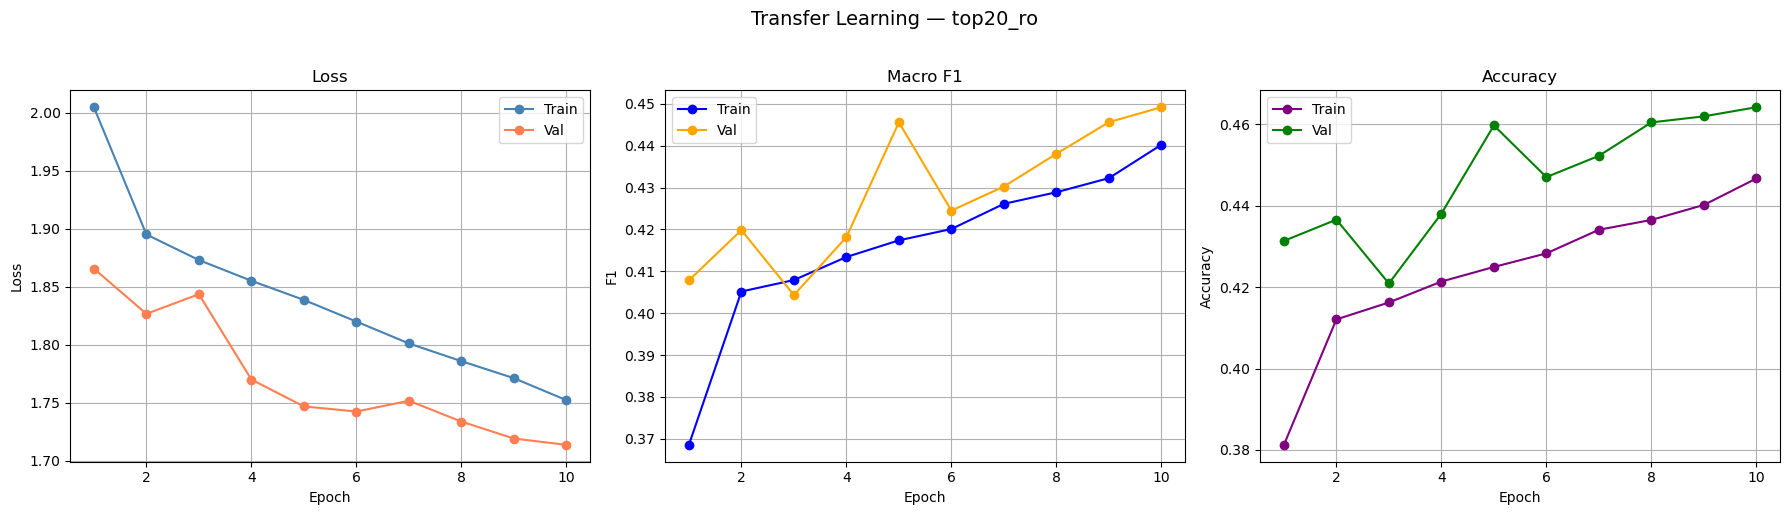


=== Rezultate Test — top20_ro ===
F1 Macro:  0.4520
Accuracy:  0.4716
                    precision    recall  f1-score   support

    Adrian Dumitru       0.51      0.64      0.57        77
Alexandra Andronie       0.30      0.35      0.32        46
  Alexandru Costea       0.56      0.38      0.45       100
  Alexandru Toader       0.67      0.53      0.59        30
     Alina Manaila       0.47      0.48      0.47        42
     Alina Popescu       0.35      0.15      0.21        48
   Andrada Giubega       0.39      0.29      0.33        41
    Andreea Tobias       0.67      0.41      0.51        29
    Bogdan Pacurar       0.33      0.45      0.38        96
   Daniela Chihaia       0.55      0.54      0.55        39
     Diana Nechita       0.70      0.75      0.73       110
  Georgiana Marina       0.41      0.42      0.42       127
       Ioana Coman       0.33      0.15      0.21        53
       Liviu Cojan       0.45      0.49      0.47       128
    Luana Pavaluca       0.4

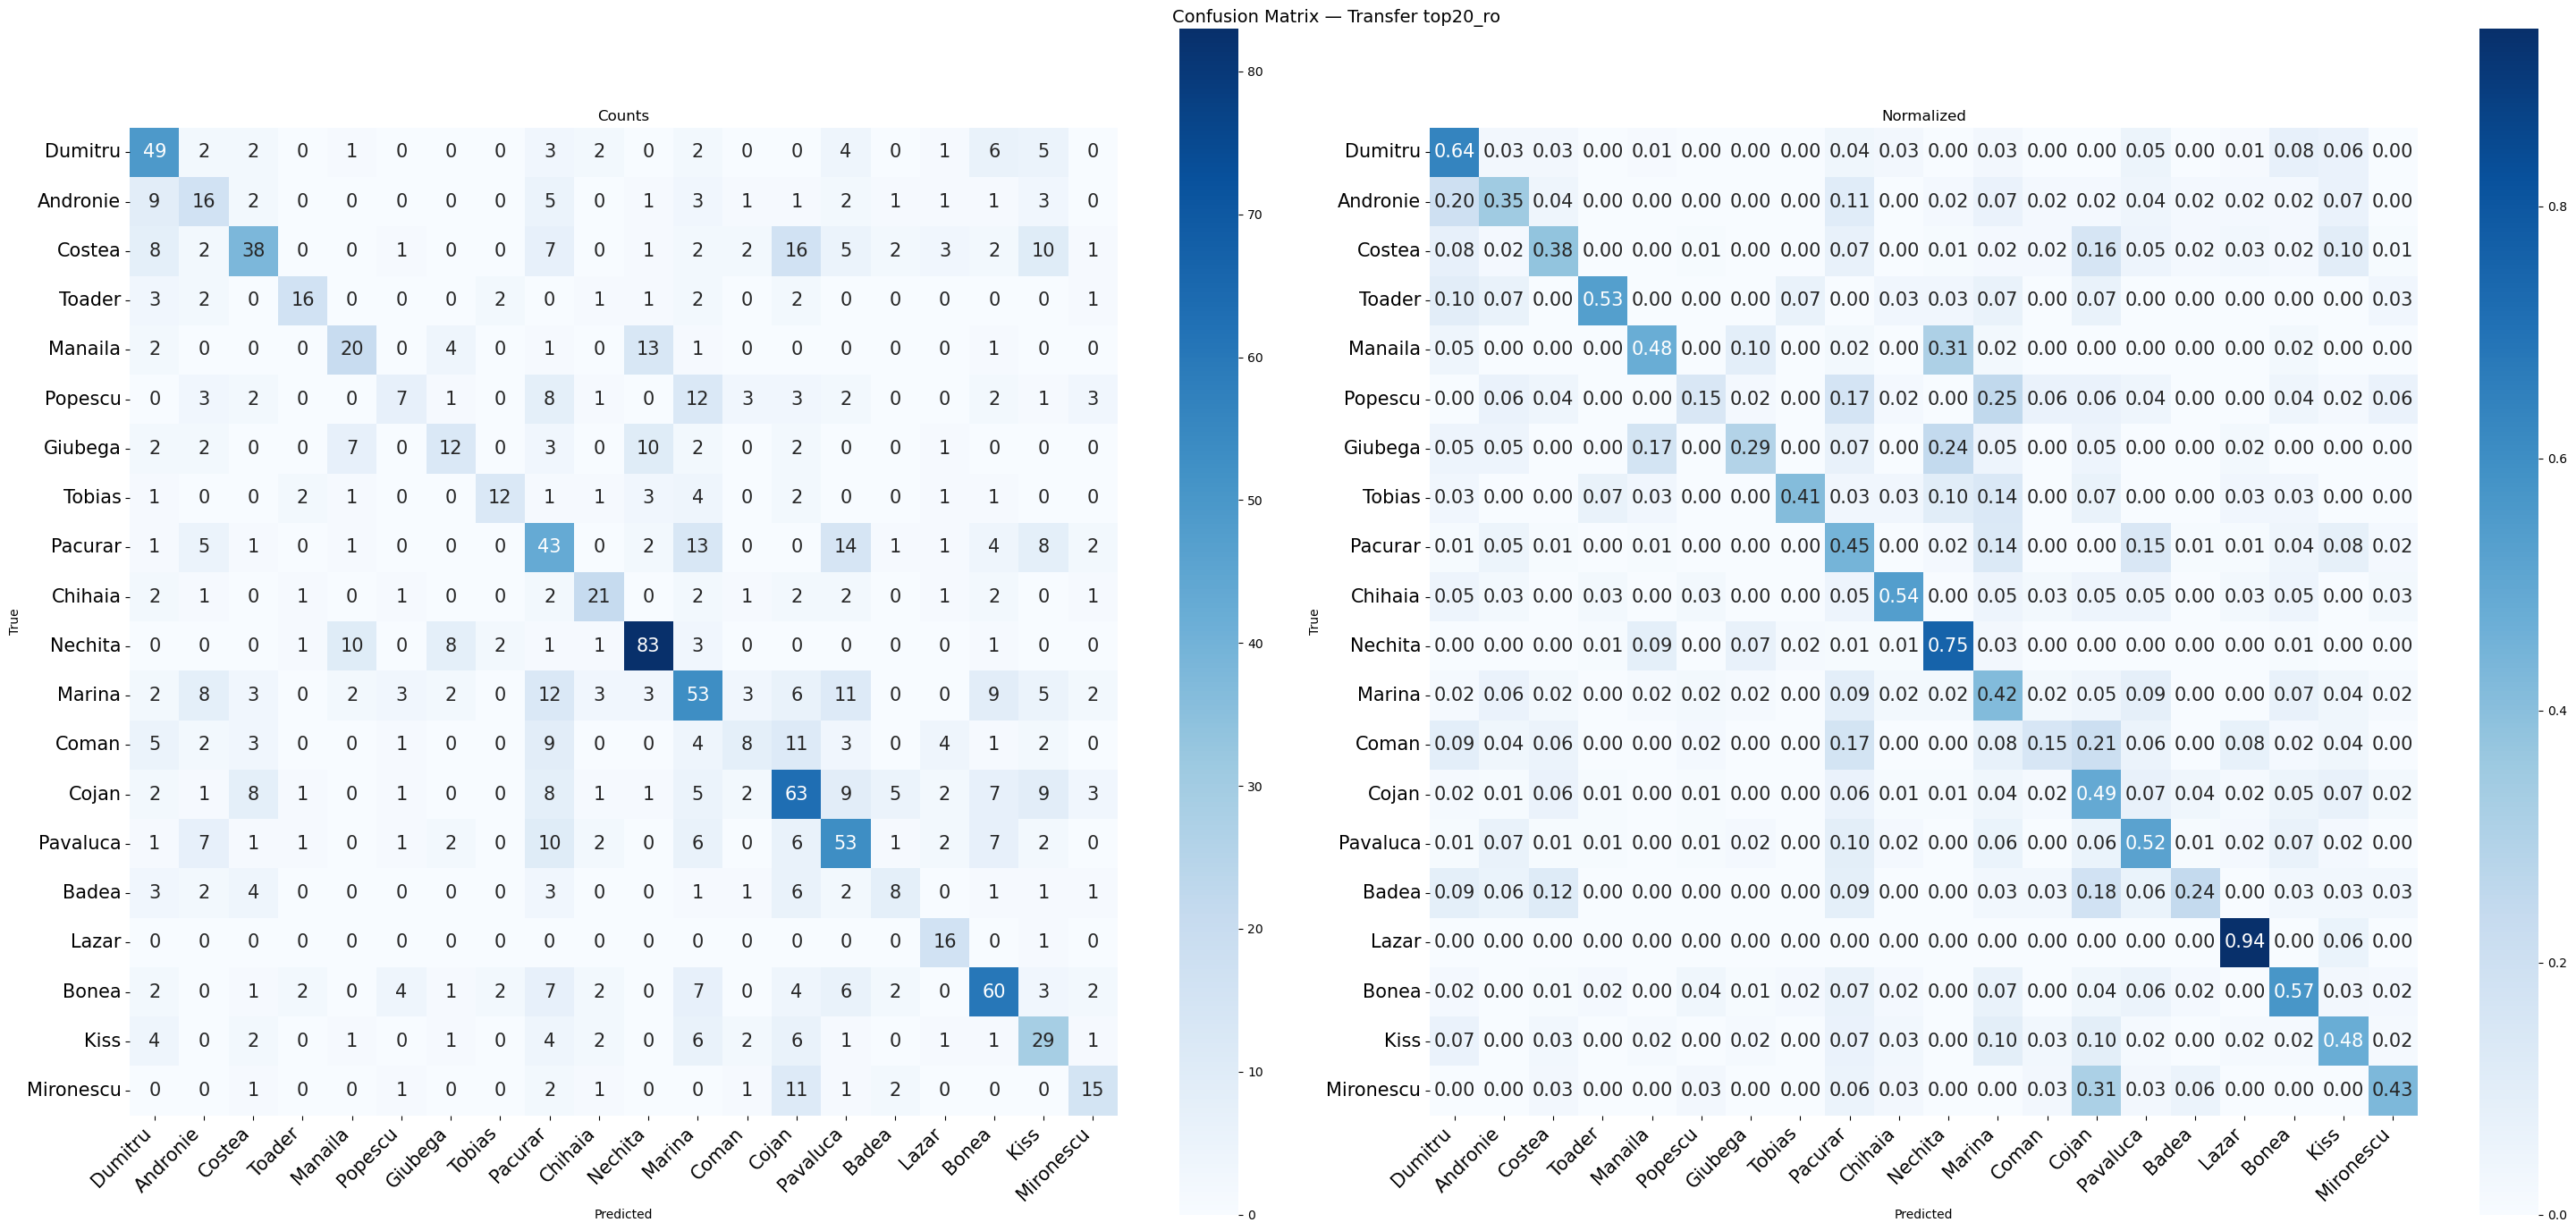


F1 Test: 0.452
Best Val F1: 0.4492


In [ ]:
result = run_transfer_experiment(
    train_df=train_df,
    val_df=val_df,
    test_df=test_df,
    pretrained_path='outputs_contrastive_2/top20_ro/best_triplet_top20_ro.pt',
    dataset_name='top20_ro',
    epochs=10,
    batch_size=16,
    lr=1e-3,
    seed=42
)

print(f"\nF1 Test: {result['f1_test']}")
print(f"Best Val F1: {result['best_val_f1']}")

# 160 minute

Pentru demo purposes only:

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BERT frozen — parametri antrenabili: classifier only
Model incarcat: outputs_transfer/top20_ro/transfer_frozen_top20_ro.pt

=== Rezultate Test — top20_ro ===
F1 Macro:  0.4520
Accuracy:  0.4716
                    precision    recall  f1-score   support

    Adrian Dumitru       0.51      0.64      0.57        77
Alexandra Andronie       0.30      0.35      0.32        46
  Alexandru Costea       0.56      0.38      0.45       100
  Alexandru Toader       0.67      0.53      0.59        30
     Alina Manaila       0.47      0.48      0.47        42
     Alina Popescu       0.35      0.15      0.21        48
   Andrada Giubega       0.39      0.29      0.33        41
    Andreea Tobias       0.67      0.41      0.51        29
    Bogdan Pacurar       0.33      0.45      0.38        96
   Daniela Chihaia       0.55      0.54      0.55        39
     Diana Nechita       0.70      0.75      0.73       110
  Georgiana Marina       0.41      0.42      0.42       127
       Ioana Coman       

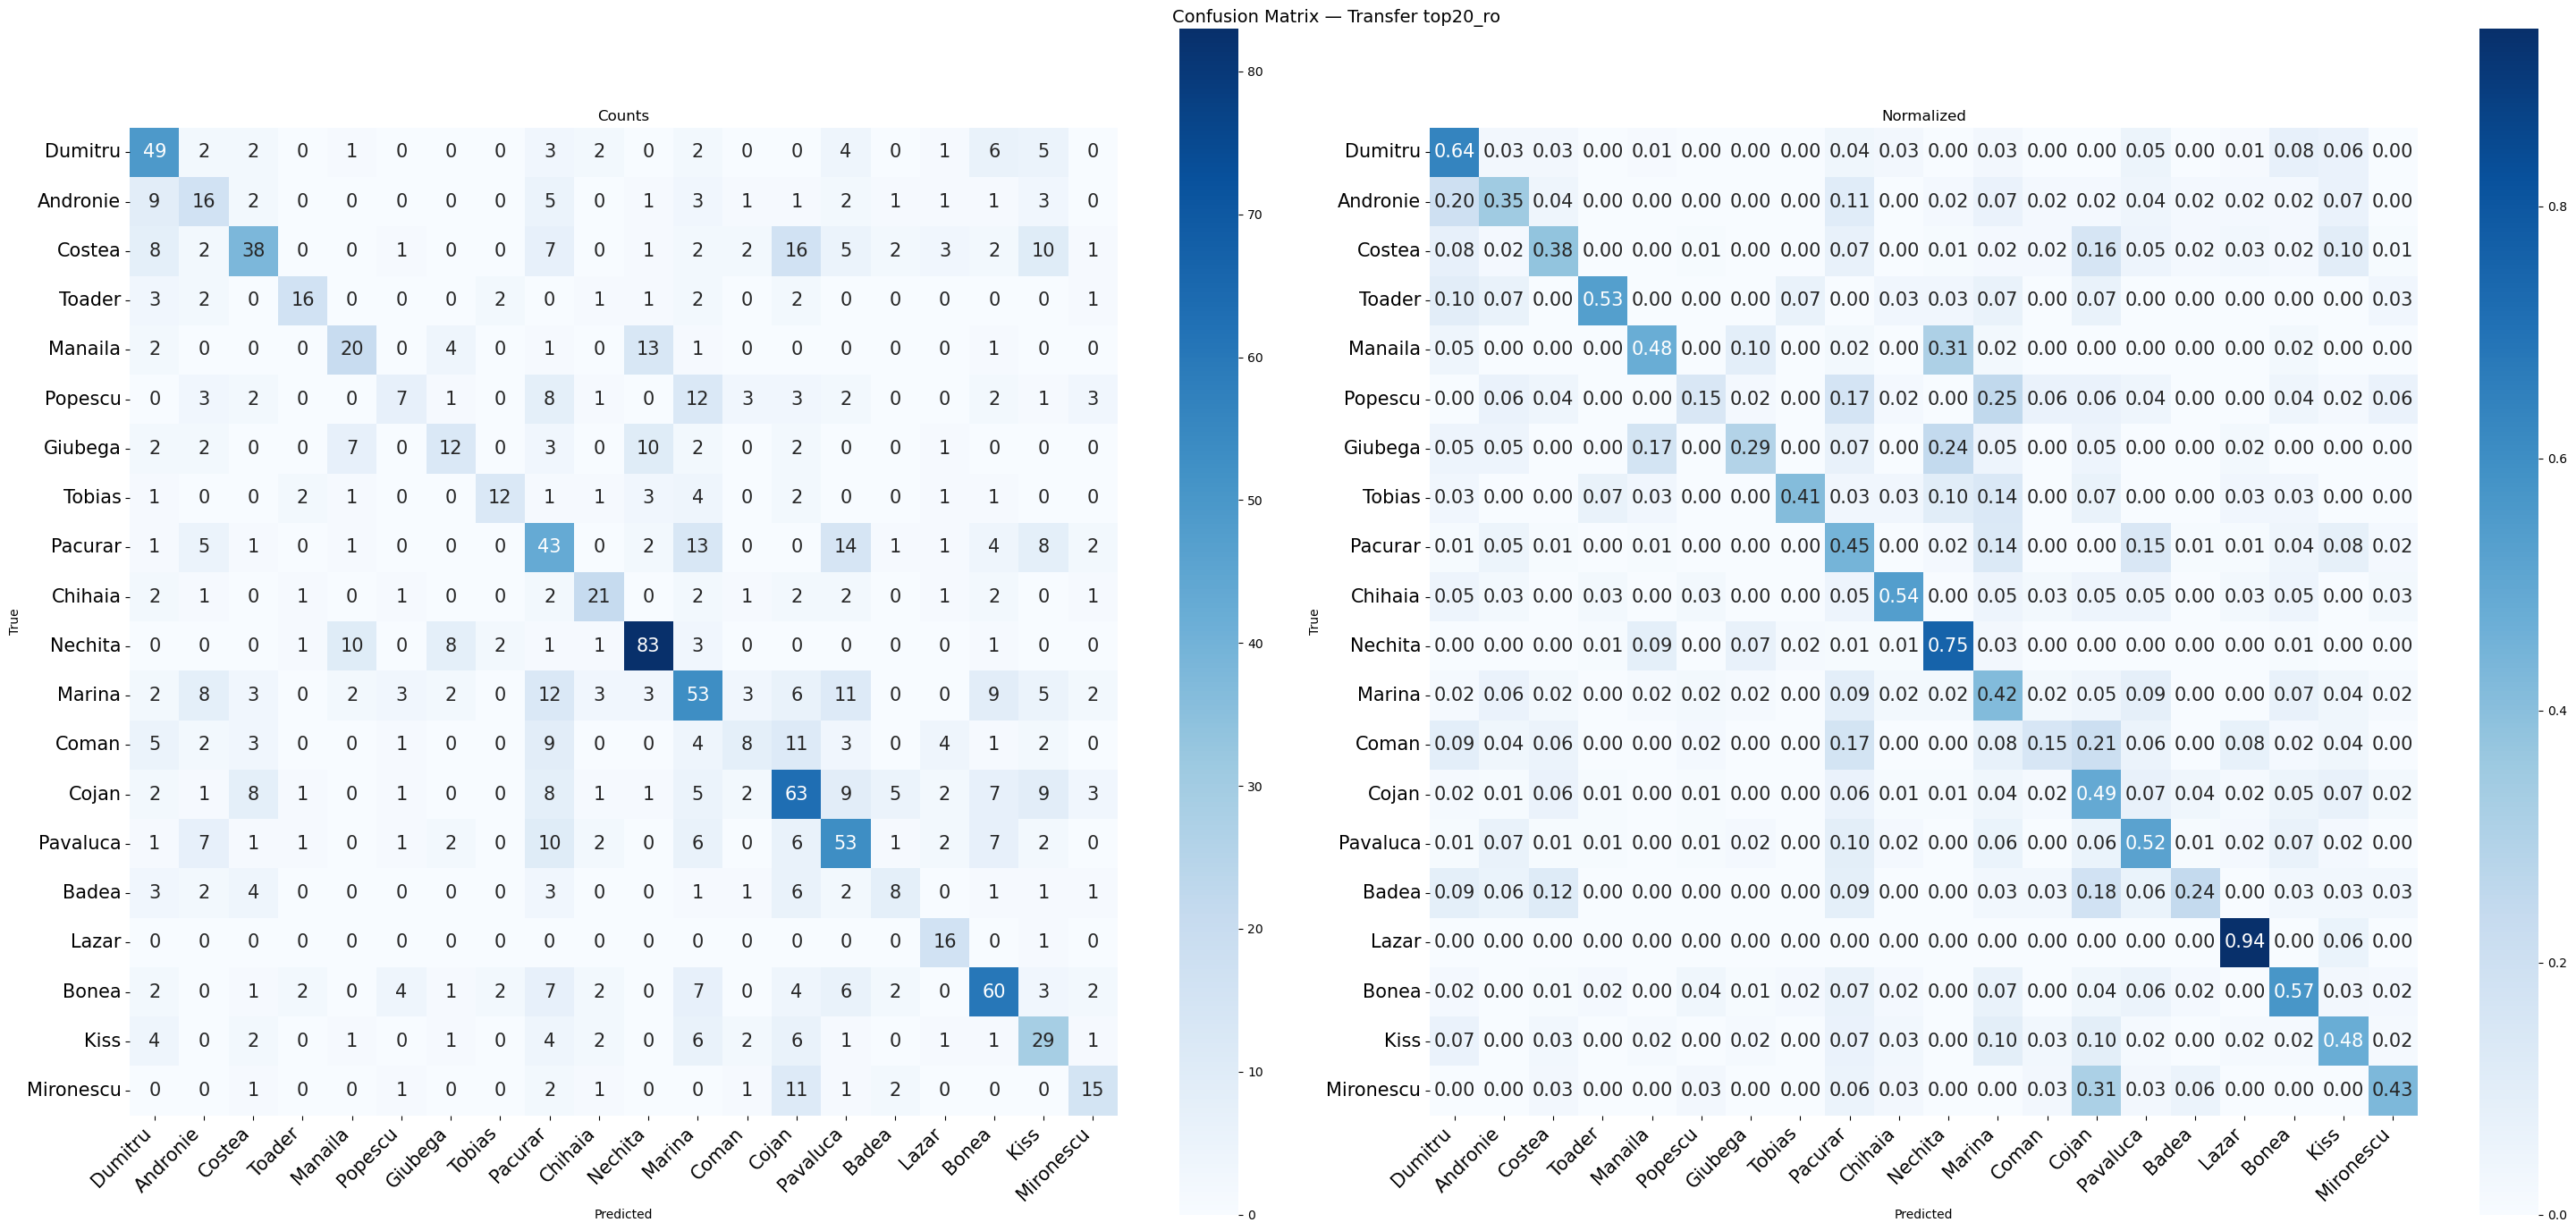

In [ ]:
preds, f1, acc = evaluate_transfer_from_checkpoint(
    model_path='outputs_transfer/top20_ro/transfer_frozen_top20_ro.pt',
    pretrained_path='outputs_contrastive_2/top20_ro/best_triplet_top20_ro.pt',
    train_df=train_df,
    test_df=test_df,
    dataset_name='top20_ro'
)
# trebuie rerulat

Romania top 40

In [19]:
train_df = pd.read_csv('final_stilo/top40_ro_train.csv')
val_df   = pd.read_csv('final_stilo/top40_ro_val.csv')
test_df  = pd.read_csv('final_stilo/top40_ro_test.csv')

Autori: 40
Train: 66991 | Val: 1790 | Test: 1761


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BERT frozen — parametri antrenabili: classifier only
classifier.weight 30720
classifier.bias 40
Epoch 1/10 — Train F1: 0.3170 | Val F1: 0.3620 | Val Acc: 0.3704
  Salvat (F1=0.3620)
Epoch 2/10 — Train F1: 0.3549 | Val F1: 0.3866 | Val Acc: 0.3989
  Salvat (F1=0.3866)
Epoch 3/10 — Train F1: 0.3571 | Val F1: 0.3799 | Val Acc: 0.3955
Epoch 4/10 — Train F1: 0.3657 | Val F1: 0.3744 | Val Acc: 0.3966
Epoch 5/10 — Train F1: 0.3698 | Val F1: 0.3810 | Val Acc: 0.3961
Epoch 6/10 — Train F1: 0.3743 | Val F1: 0.3923 | Val Acc: 0.4078
  Salvat (F1=0.3923)
Epoch 7/10 — Train F1: 0.3818 | Val F1: 0.3901 | Val Acc: 0.4000
Epoch 8/10 — Train F1: 0.3889 | Val F1: 0.3950 | Val Acc: 0.4050
  Salvat (F1=0.3950)
Epoch 9/10 — Train F1: 0.3905 | Val F1: 0.4062 | Val Acc: 0.4117
  Salvat (F1=0.4062)
Epoch 10/10 — Train F1: 0.3992 | Val F1: 0.4064 | Val Acc: 0.4173
  Salvat (F1=0.4064)

Best Val F1: 0.4064
Salvat: outputs_transfer/top40_ro/curves_transfer_summary_top40_ro.png


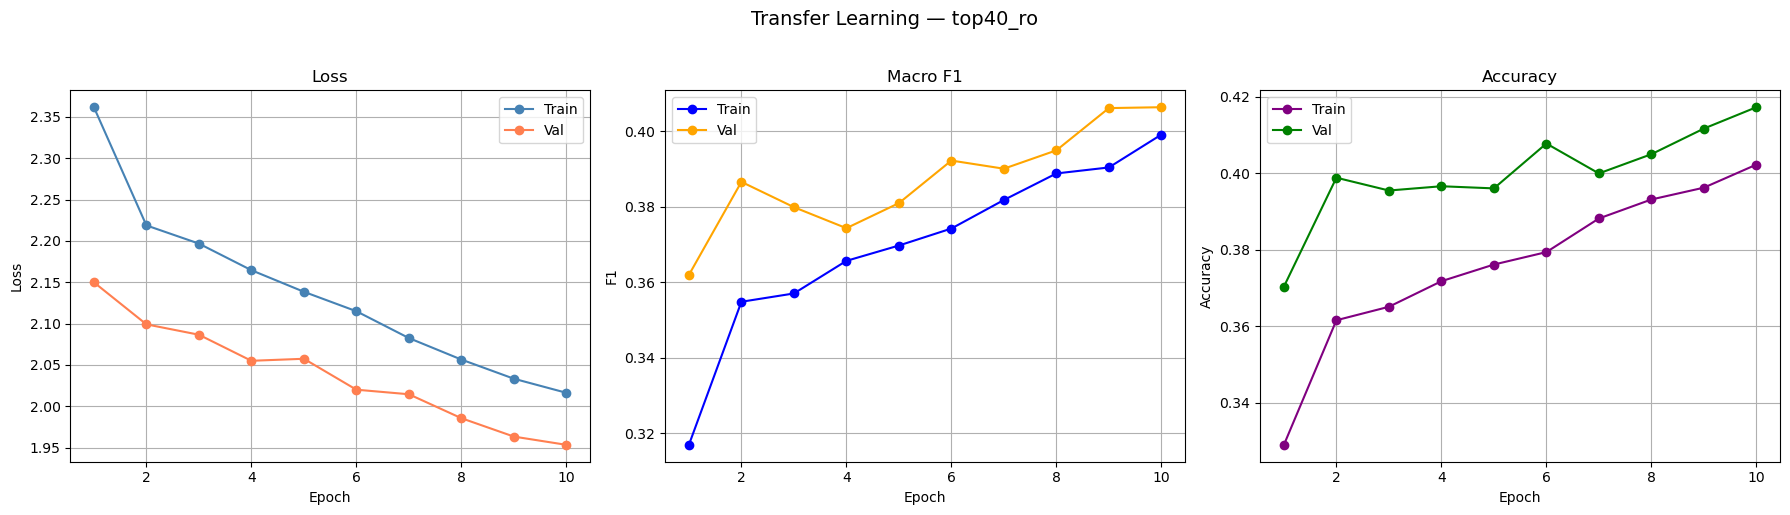


=== Rezultate Test — top40_ro ===
F1 Macro:  0.4051
Accuracy:  0.4304
                      precision    recall  f1-score   support

      Adrian Dumitru       0.57      0.60      0.59        77
  Alexandra Andronie       0.31      0.37      0.34        46
    Alexandru Costea       0.44      0.30      0.36       100
    Alexandru Toader       0.31      0.37      0.33        30
       Alina Manaila       0.50      0.45      0.47        42
       Alina Popescu       0.23      0.15      0.18        48
        Ana Petrescu       0.67      0.73      0.70        22
     Anca Dumitrescu       0.76      0.94      0.84        17
     Andrada Giubega       0.48      0.29      0.36        41
      Andreea Neblea       0.57      0.42      0.48        31
      Andreea Tobias       0.22      0.14      0.17        29
      Bogdan Pacurar       0.30      0.45      0.36        96
       Carmen Zanfir       0.65      0.45      0.54        33
    Catalin Costache       0.37      0.54      0.44        2

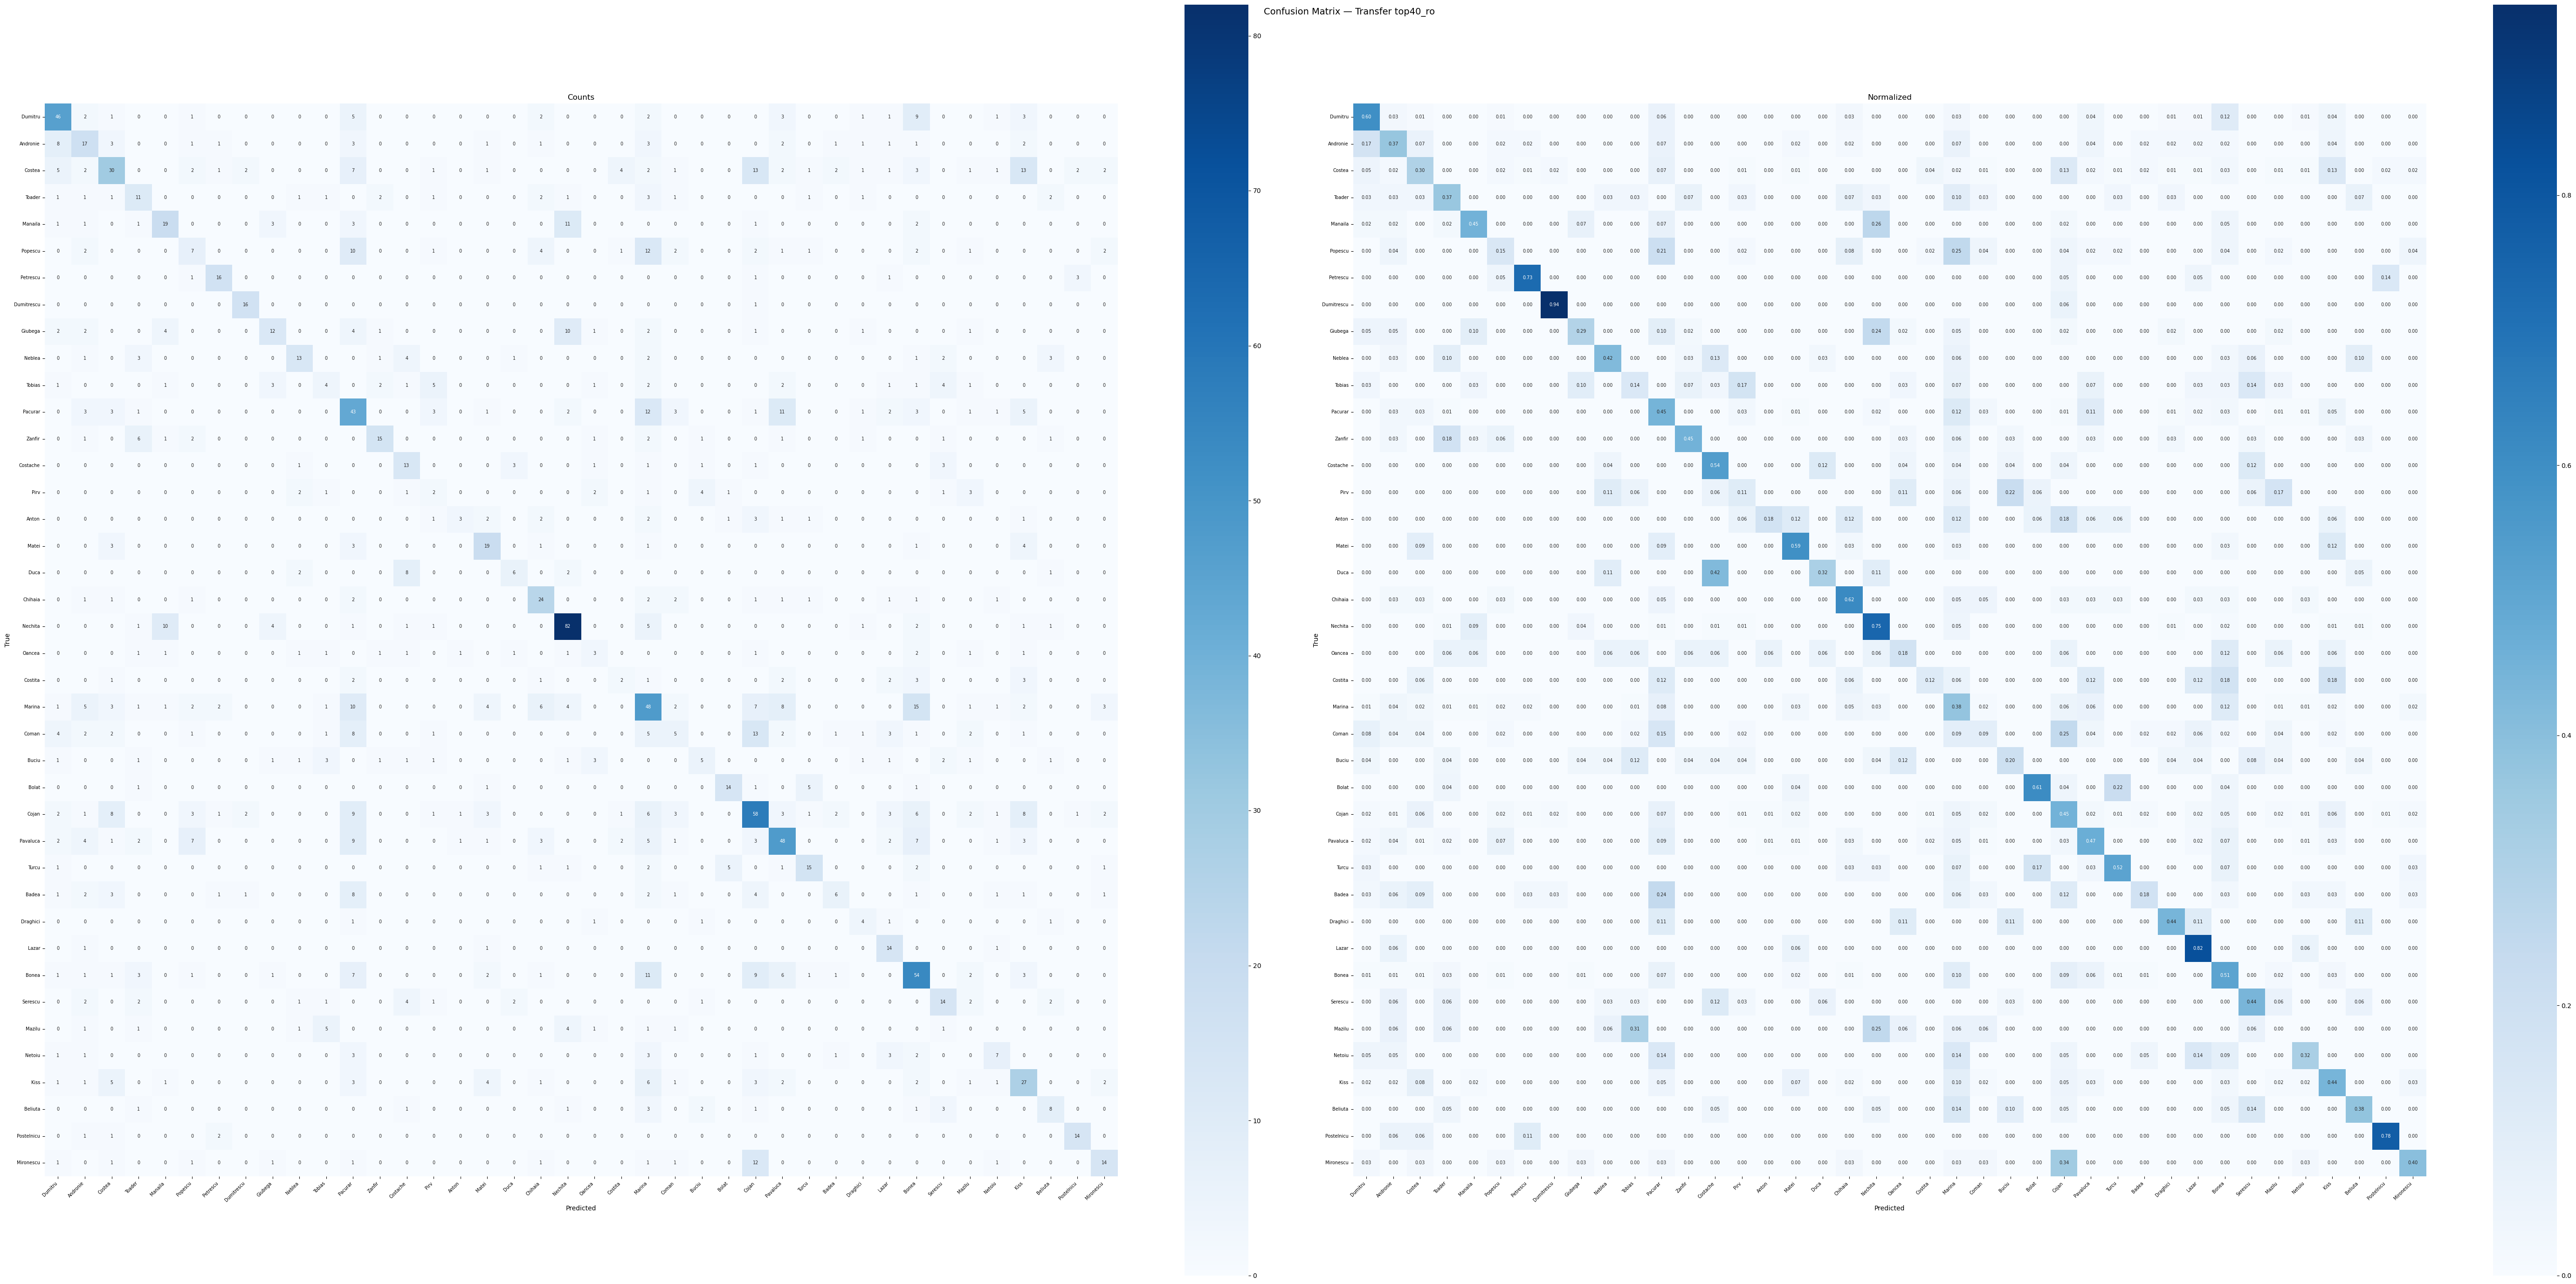


F1 Test: 0.4051
Best Val F1: 0.4064


In [ ]:
result = run_transfer_experiment(
    train_df=train_df,
    val_df=val_df,
    test_df=test_df,
    pretrained_path='outputs_contrastive_2/top40_ro/best_triplet_top40_ro.pt',
    dataset_name='top40_ro',
    epochs=10,
    batch_size=16,
    lr=1e-3,
    seed=42
)

print(f"\nF1 Test: {result['f1_test']}")
print(f"Best Val F1: {result['best_val_f1']}")
# 221 minute

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BERT frozen — parametri antrenabili: classifier only
Model incarcat: outputs_transfer/top40_ro/transfer_frozen_top40_ro.pt

=== Rezultate Test — top40_ro ===
F1 Macro:  0.4051
Accuracy:  0.4304
                      precision    recall  f1-score   support

      Adrian Dumitru       0.57      0.60      0.59        77
  Alexandra Andronie       0.31      0.37      0.34        46
    Alexandru Costea       0.44      0.30      0.36       100
    Alexandru Toader       0.31      0.37      0.33        30
       Alina Manaila       0.50      0.45      0.47        42
       Alina Popescu       0.23      0.15      0.18        48
        Ana Petrescu       0.67      0.73      0.70        22
     Anca Dumitrescu       0.76      0.94      0.84        17
     Andrada Giubega       0.48      0.29      0.36        41
      Andreea Neblea       0.57      0.42      0.48        31
      Andreea Tobias       0.22      0.14      0.17        29
      Bogdan Pacurar       0.30      0.45      0.36        96

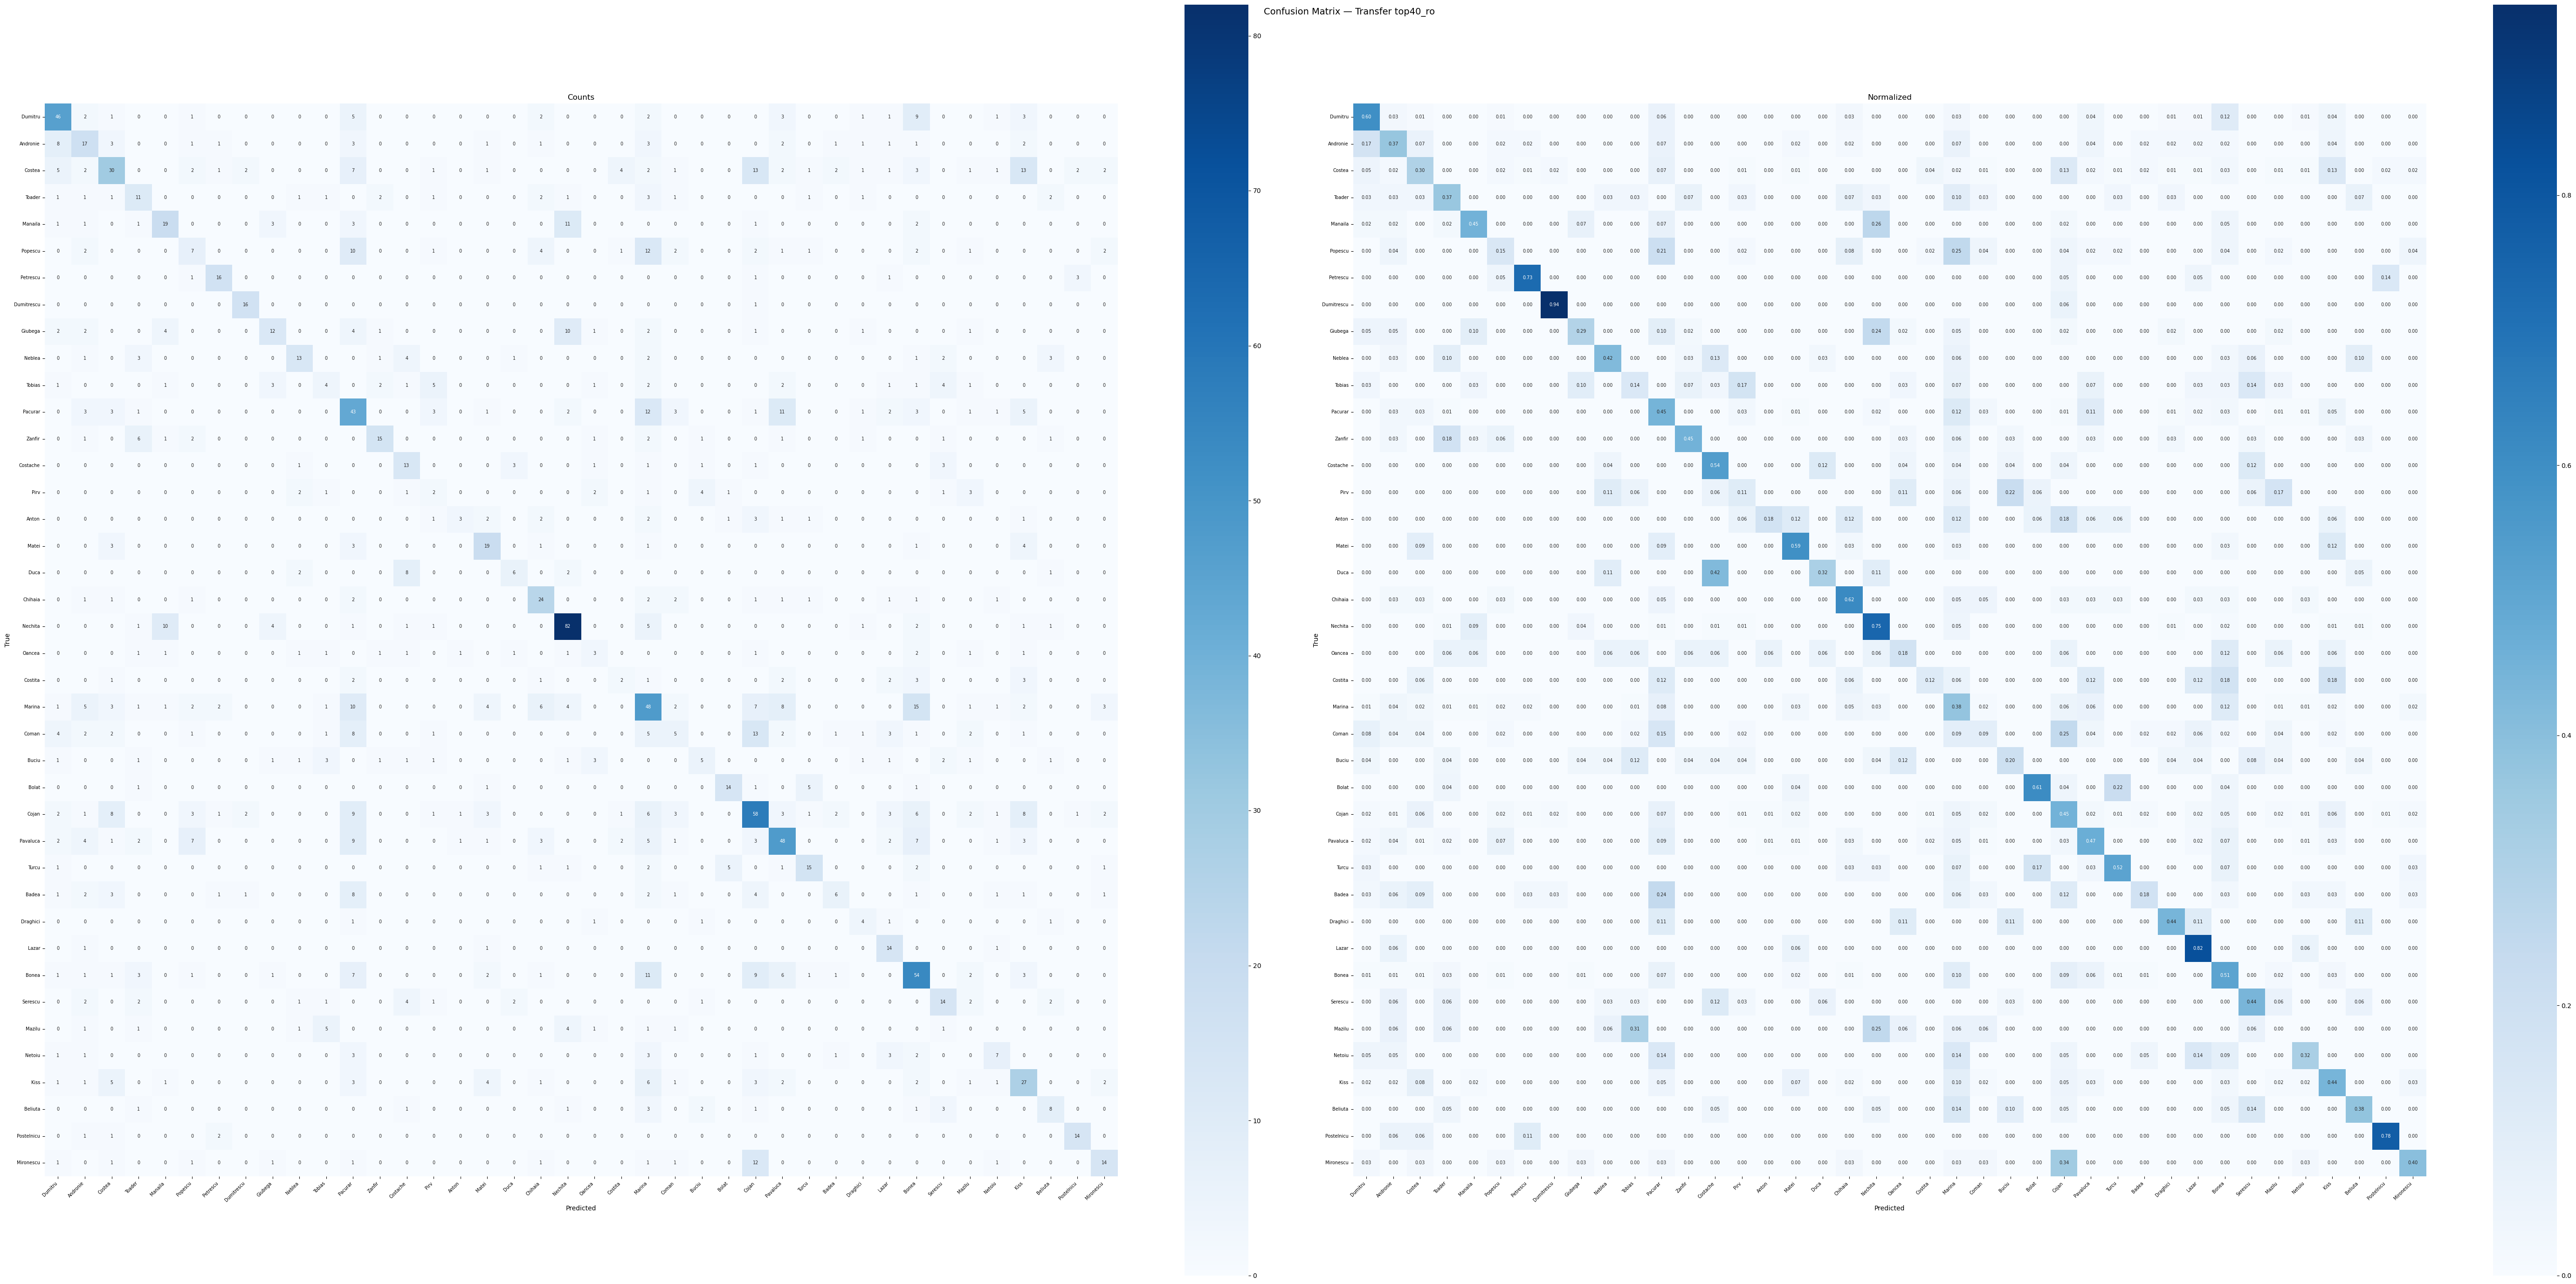

In [22]:
preds, f1, acc = evaluate_transfer_from_checkpoint(
    model_path='outputs_transfer/top40_ro/transfer_frozen_top40_ro.pt',
    pretrained_path='outputs_contrastive_2/top40_ro/best_triplet_top40_ro.pt',
    train_df=train_df,
    test_df=test_df,
    dataset_name='top40_ro'
)

Moldova top 20

In [23]:
train_df = pd.read_csv('final_stilo/top20_mo_train.csv')
val_df   = pd.read_csv('final_stilo/top20_mo_val.csv')
test_df  = pd.read_csv('final_stilo/top20_mo_test.csv')

Autori: 20
Train: 39332 | Val: 4916 | Test: 4917


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BERT frozen — parametri antrenabili: classifier only
classifier.weight 15360
classifier.bias 20
Epoch 1/10 — Train F1: 0.3654 | Val F1: 0.4139 | Val Acc: 0.4384
  Salvat (F1=0.4139)
Epoch 2/10 — Train F1: 0.4075 | Val F1: 0.4265 | Val Acc: 0.4457
  Salvat (F1=0.4265)
Epoch 3/10 — Train F1: 0.4119 | Val F1: 0.4275 | Val Acc: 0.4561
  Salvat (F1=0.4275)
Epoch 4/10 — Train F1: 0.4188 | Val F1: 0.4325 | Val Acc: 0.4597
  Salvat (F1=0.4325)
Epoch 5/10 — Train F1: 0.4195 | Val F1: 0.4333 | Val Acc: 0.4616
  Salvat (F1=0.4333)
Epoch 6/10 — Train F1: 0.4230 | Val F1: 0.4412 | Val Acc: 0.4614
  Salvat (F1=0.4412)
Epoch 7/10 — Train F1: 0.4314 | Val F1: 0.4324 | Val Acc: 0.4650
Epoch 8/10 — Train F1: 0.4361 | Val F1: 0.4396 | Val Acc: 0.4670
Epoch 9/10 — Train F1: 0.4387 | Val F1: 0.4509 | Val Acc: 0.4746
  Salvat (F1=0.4509)
Epoch 10/10 — Train F1: 0.4438 | Val F1: 0.4447 | Val Acc: 0.4707

Best Val F1: 0.4509
Salvat: outputs_transfer/top20_mo/curves_transfer_summary_top20_mo.png


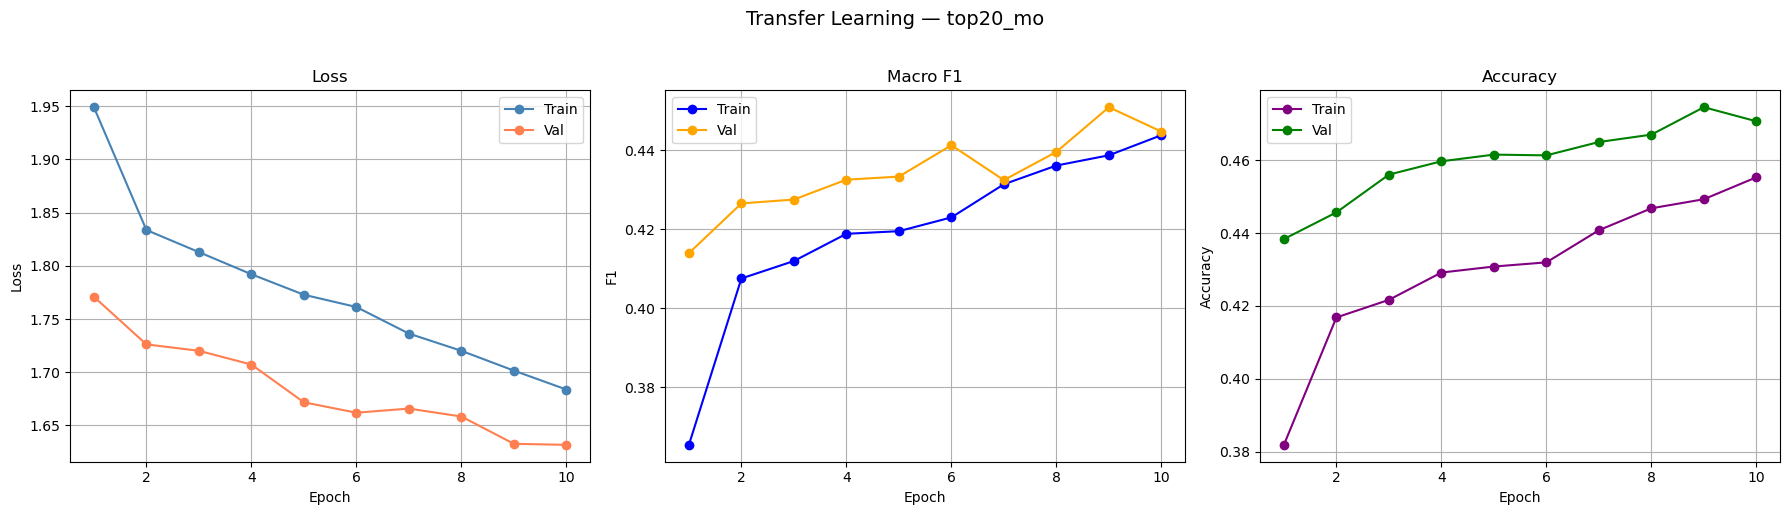


=== Rezultate Test — top20_mo ===
F1 Macro:  0.4293
Accuracy:  0.4606
                    precision    recall  f1-score   support

     Aliona Ciurca       0.65      0.47      0.55       150
 Ana-Maria Dolghii       0.33      0.17      0.23       121
     Cristian Sava       0.38      0.31      0.34       328
    Cristina Dulea       0.34      0.20      0.25       119
    Cristina Mirca       0.37      0.30      0.33       271
  Cristina Popescu       0.26      0.21      0.23       289
      Diana Gatcan       0.47      0.55      0.51       269
     Diana Severin       0.59      0.46      0.52       284
Ecaterina Arvintii       0.49      0.50      0.49       164
  Malvina Cojocari       0.25      0.12      0.16       131
    Marina Ciobanu       0.62      0.42      0.50       175
     Maxim Stratan       0.52      0.54      0.53       230
  Mihaela Conovali       0.50      0.54      0.52       379
     Milena Onisim       0.58      0.72      0.64       279
  Nicoleta Braghis       0.4

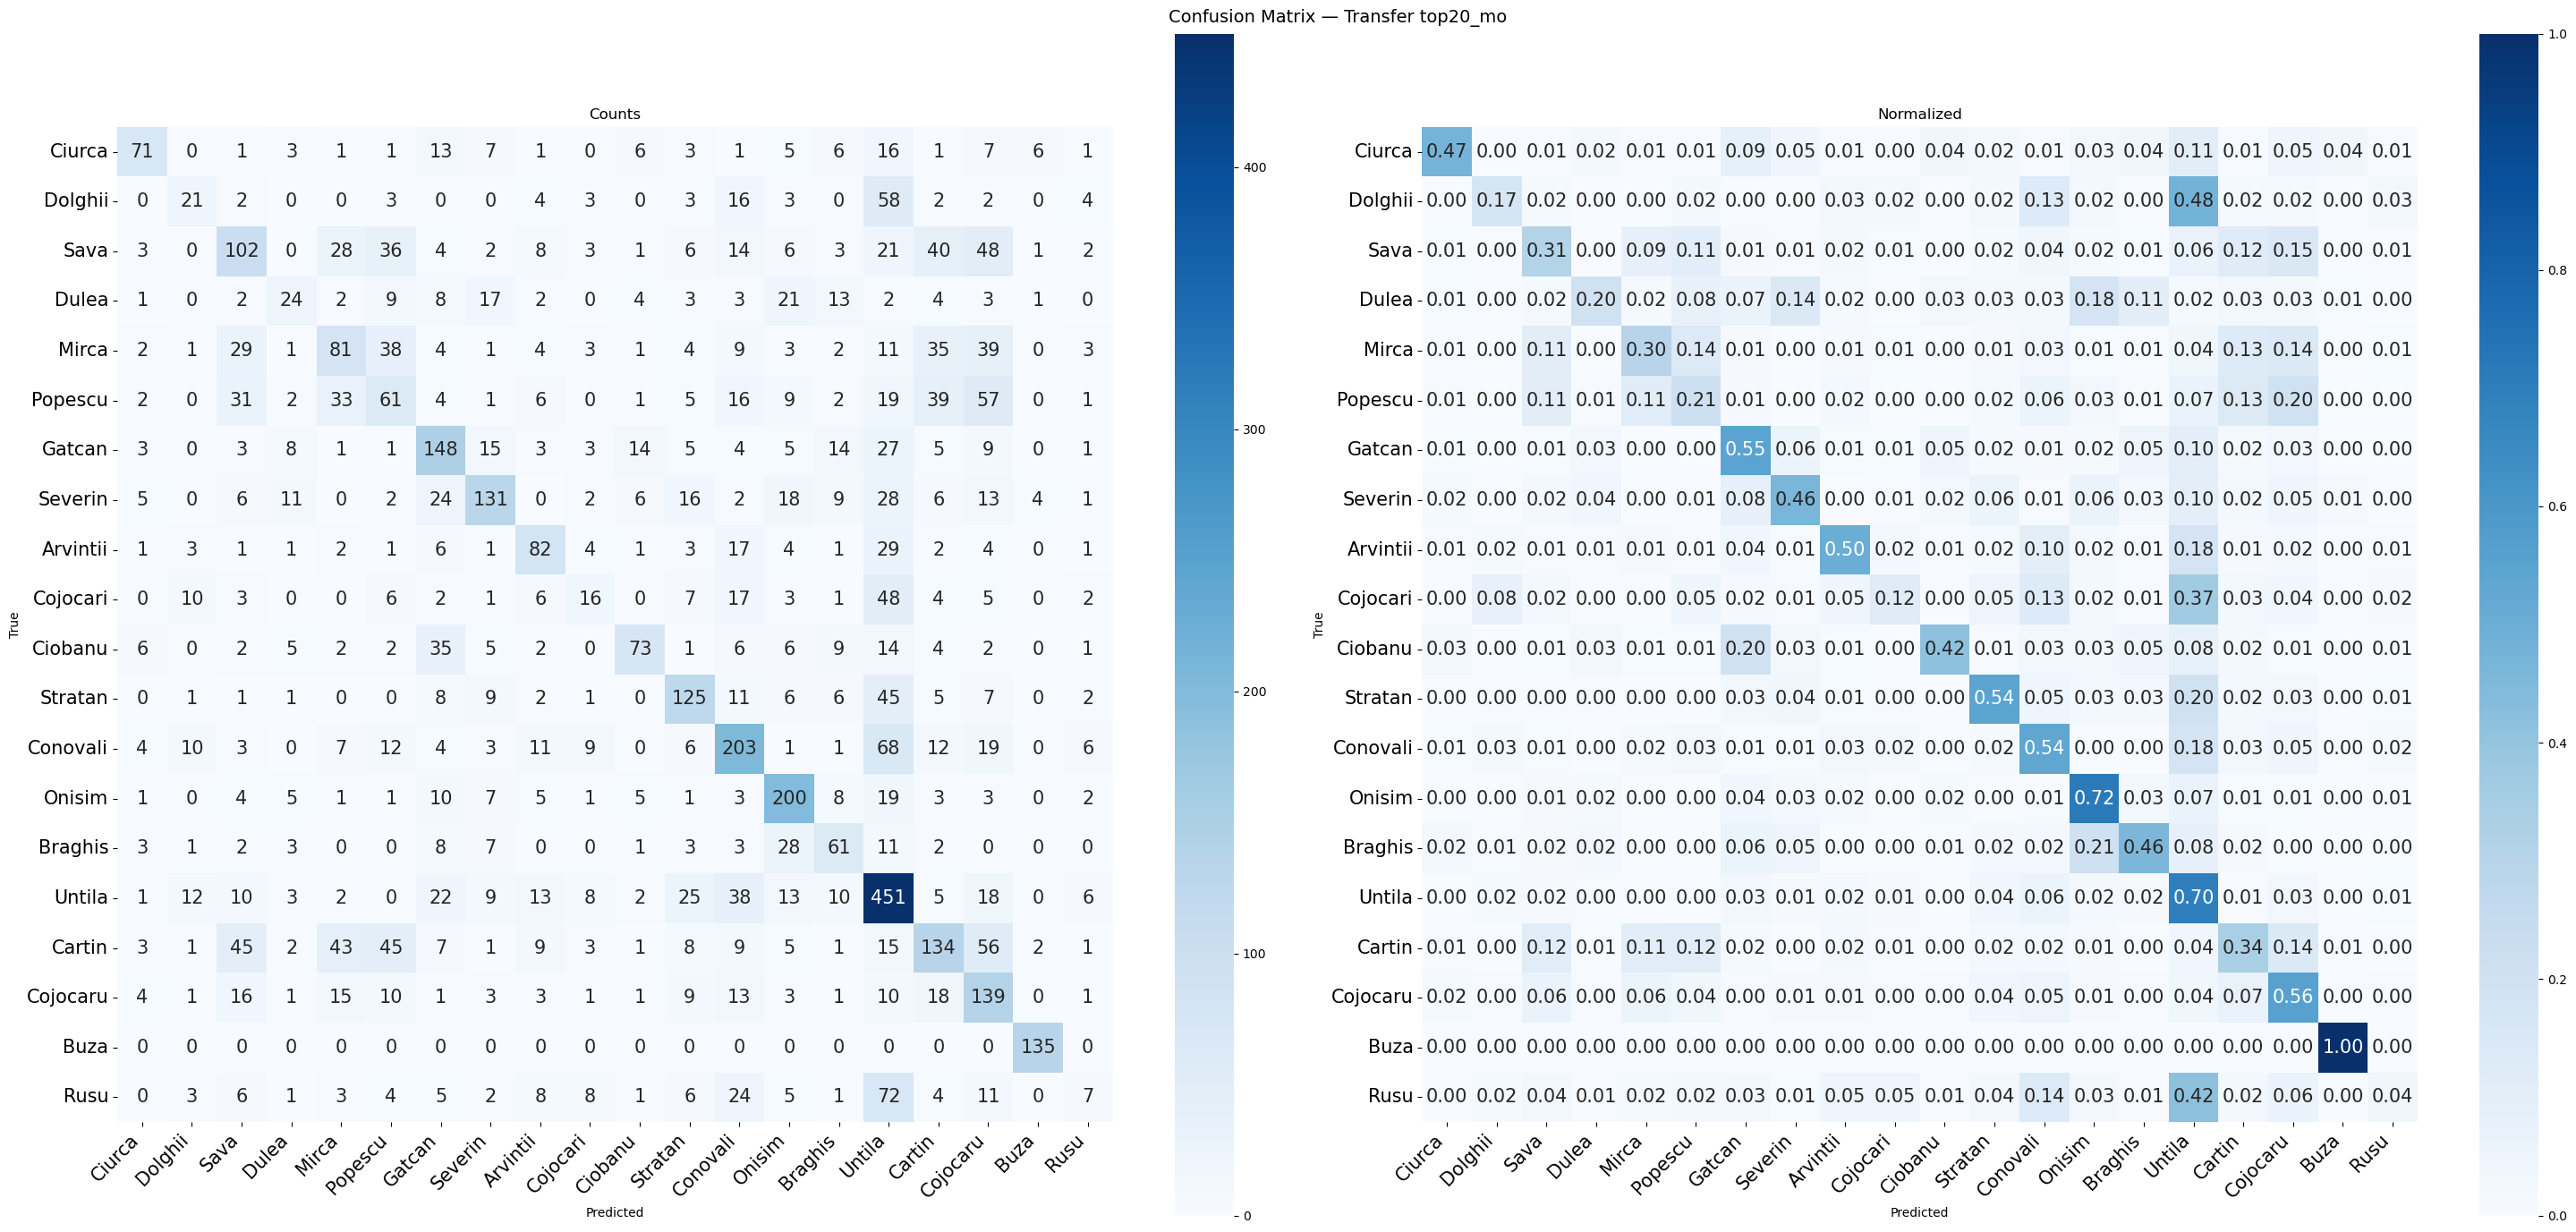


F1 Test: 0.4293
Best Val F1: 0.4509


In [ ]:
result = run_transfer_experiment(
    train_df=train_df,
    val_df=val_df,
    test_df=test_df,
    pretrained_path='outputs_contrastive_2/top20_mo/best_triplet_top20_mo.pt',
    dataset_name='top20_mo',
    epochs=10,
    batch_size=16,
    lr=1e-3,
    seed=42
)

print(f"\nF1 Test: {result['f1_test']}")
print(f"Best Val F1: {result['best_val_f1']}")
# 138 minute

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BERT frozen — parametri antrenabili: classifier only
Model incarcat: outputs_transfer/top20_mo/transfer_frozen_top20_mo.pt

=== Rezultate Test — top20_mo ===
F1 Macro:  0.4293
Accuracy:  0.4606
                    precision    recall  f1-score   support

     Aliona Ciurca       0.65      0.47      0.55       150
 Ana-Maria Dolghii       0.33      0.17      0.23       121
     Cristian Sava       0.38      0.31      0.34       328
    Cristina Dulea       0.34      0.20      0.25       119
    Cristina Mirca       0.37      0.30      0.33       271
  Cristina Popescu       0.26      0.21      0.23       289
      Diana Gatcan       0.47      0.55      0.51       269
     Diana Severin       0.59      0.46      0.52       284
Ecaterina Arvintii       0.49      0.50      0.49       164
  Malvina Cojocari       0.25      0.12      0.16       131
    Marina Ciobanu       0.62      0.42      0.50       175
     Maxim Stratan       0.52      0.54      0.53       230
  Mihaela Conovali       

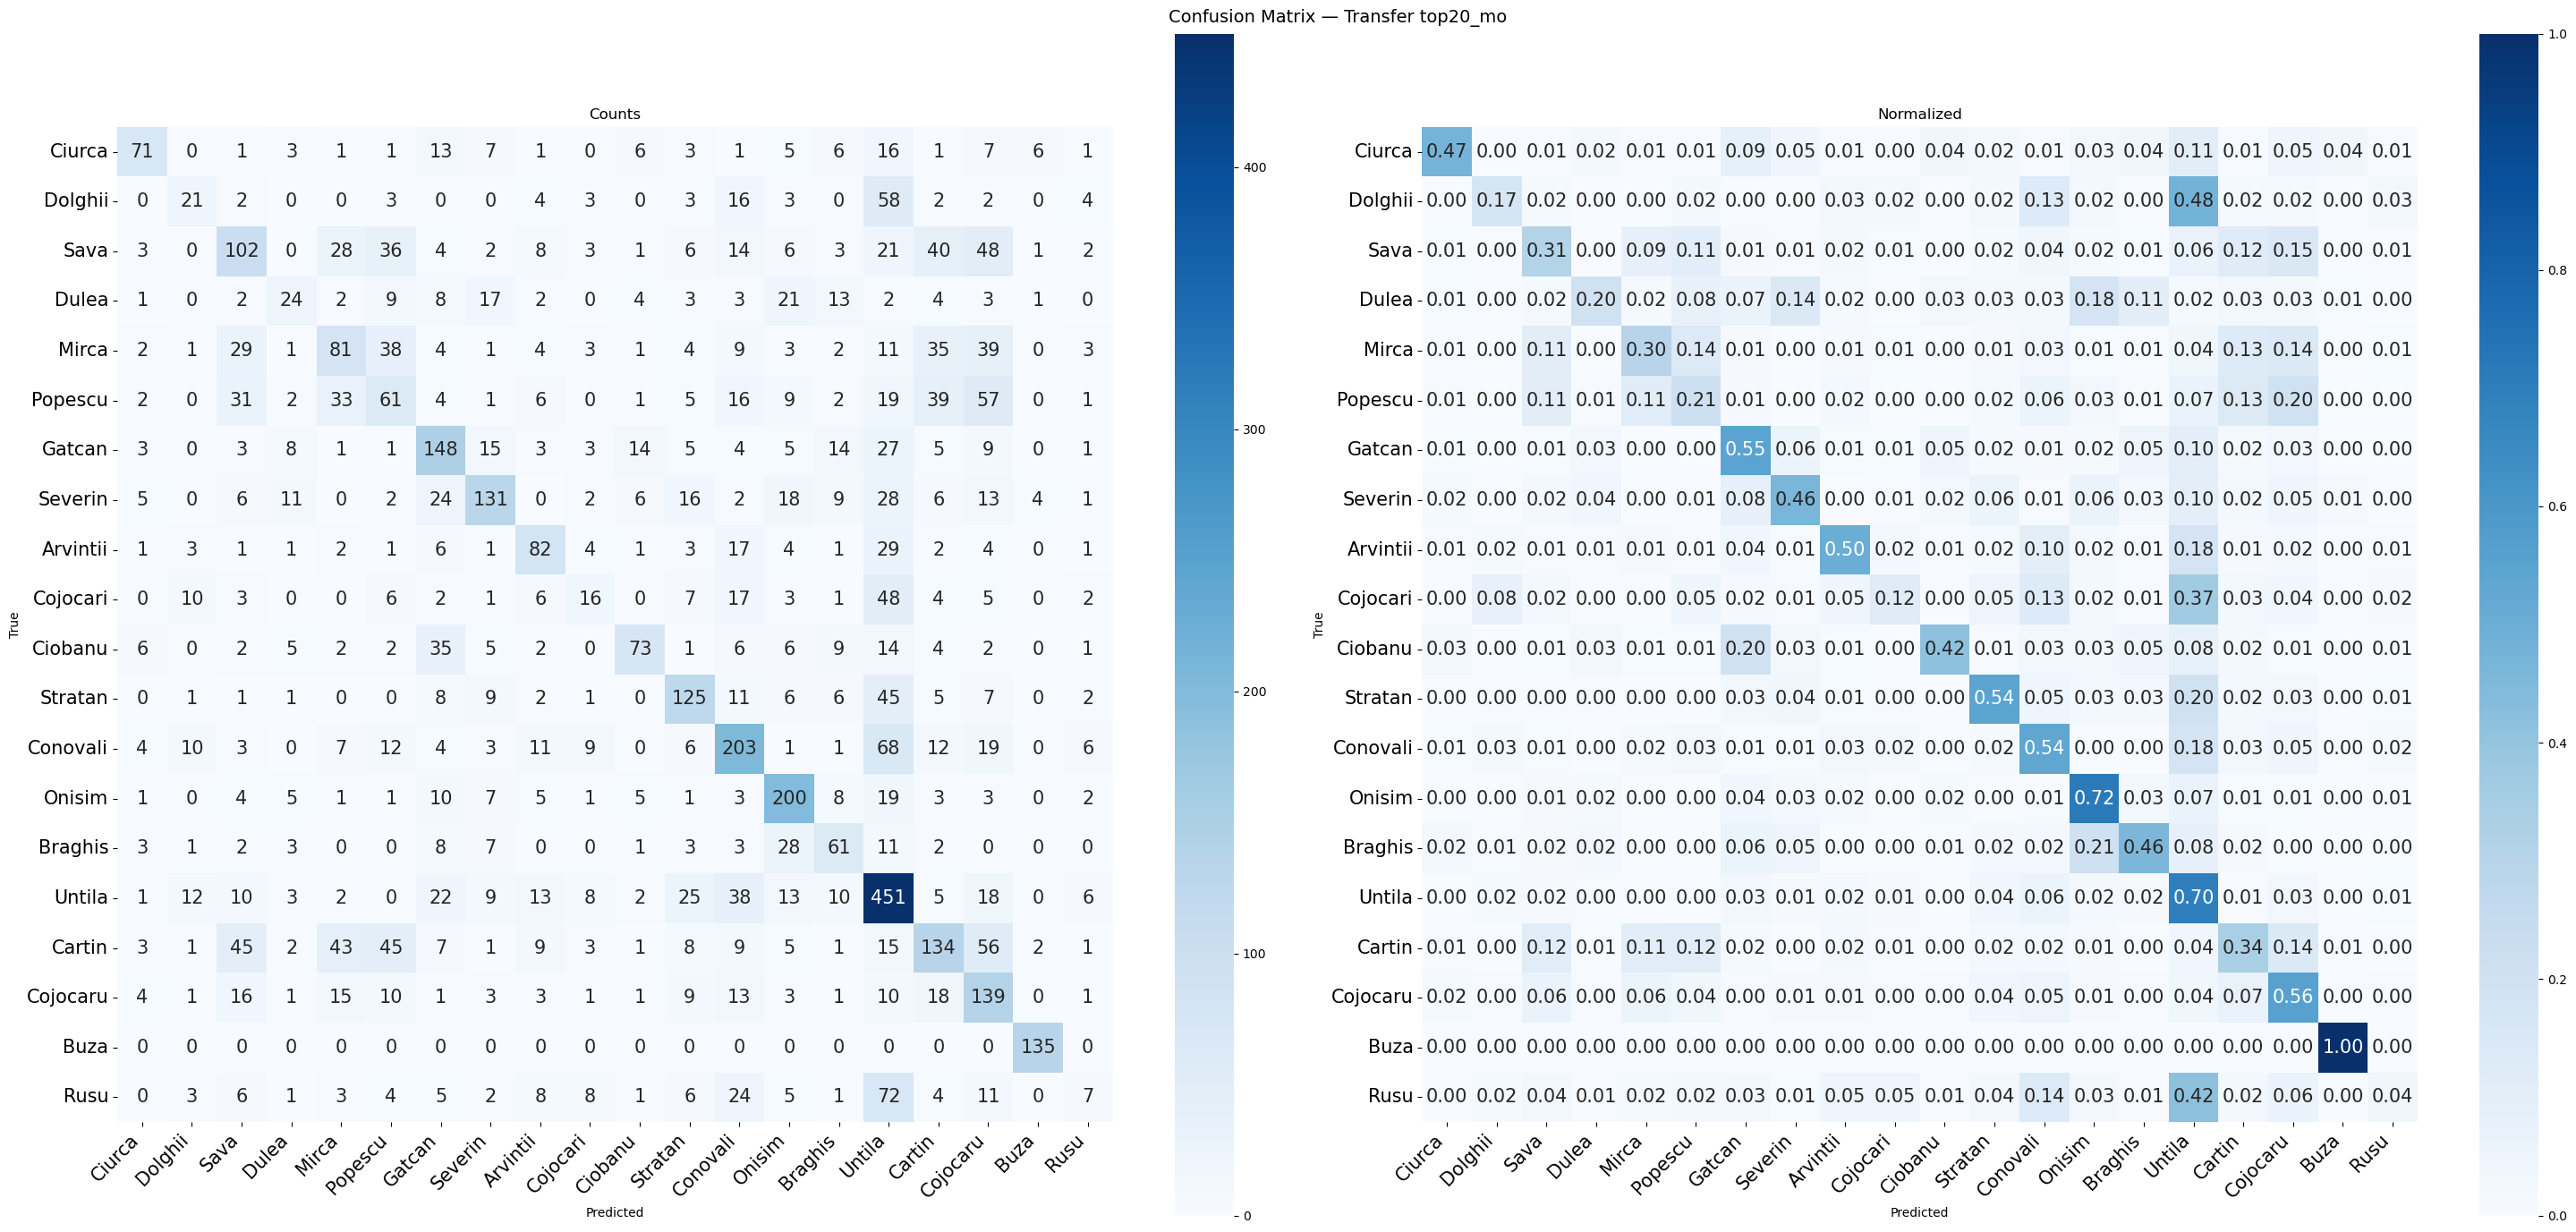

In [25]:
preds, f1, acc = evaluate_transfer_from_checkpoint(
    model_path='outputs_transfer/top20_mo/transfer_frozen_top20_mo.pt',
    pretrained_path='outputs_contrastive_2/top20_mo/best_triplet_top20_mo.pt',
    train_df=train_df,
    test_df=test_df,
    dataset_name='top20_mo'
)

Moldova top 40

In [26]:
train_df = pd.read_csv('final_stilo/top40_mo_train.csv')
val_df   = pd.read_csv('final_stilo/top40_mo_val.csv')
test_df  = pd.read_csv('final_stilo/top40_mo_test.csv')

Autori: 40
Train: 47215 | Val: 5902 | Test: 5902


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BERT frozen — parametri antrenabili: classifier only
classifier.weight 30720
classifier.bias 40
Epoch 1/10 — Train F1: 0.2732 | Val F1: 0.2647 | Val Acc: 0.3445
  Salvat (F1=0.2647)
Epoch 2/10 — Train F1: 0.3113 | Val F1: 0.2752 | Val Acc: 0.3607
  Salvat (F1=0.2752)
Epoch 3/10 — Train F1: 0.3207 | Val F1: 0.2785 | Val Acc: 0.3587
  Salvat (F1=0.2785)
Epoch 4/10 — Train F1: 0.3225 | Val F1: 0.2860 | Val Acc: 0.3677
  Salvat (F1=0.2860)
Epoch 5/10 — Train F1: 0.3259 | Val F1: 0.2730 | Val Acc: 0.3546
Epoch 6/10 — Train F1: 0.3366 | Val F1: 0.3005 | Val Acc: 0.3812
  Salvat (F1=0.3005)
Epoch 7/10 — Train F1: 0.3380 | Val F1: 0.2908 | Val Acc: 0.3865
Epoch 8/10 — Train F1: 0.3452 | Val F1: 0.3014 | Val Acc: 0.3861
  Salvat (F1=0.3014)
Epoch 9/10 — Train F1: 0.3507 | Val F1: 0.3008 | Val Acc: 0.3894
Epoch 10/10 — Train F1: 0.3552 | Val F1: 0.3017 | Val Acc: 0.3911
  Salvat (F1=0.3017)

Best Val F1: 0.3017
Salvat: outputs_transfer/top40_mo/curves_transfer_summary_top40_mo.png


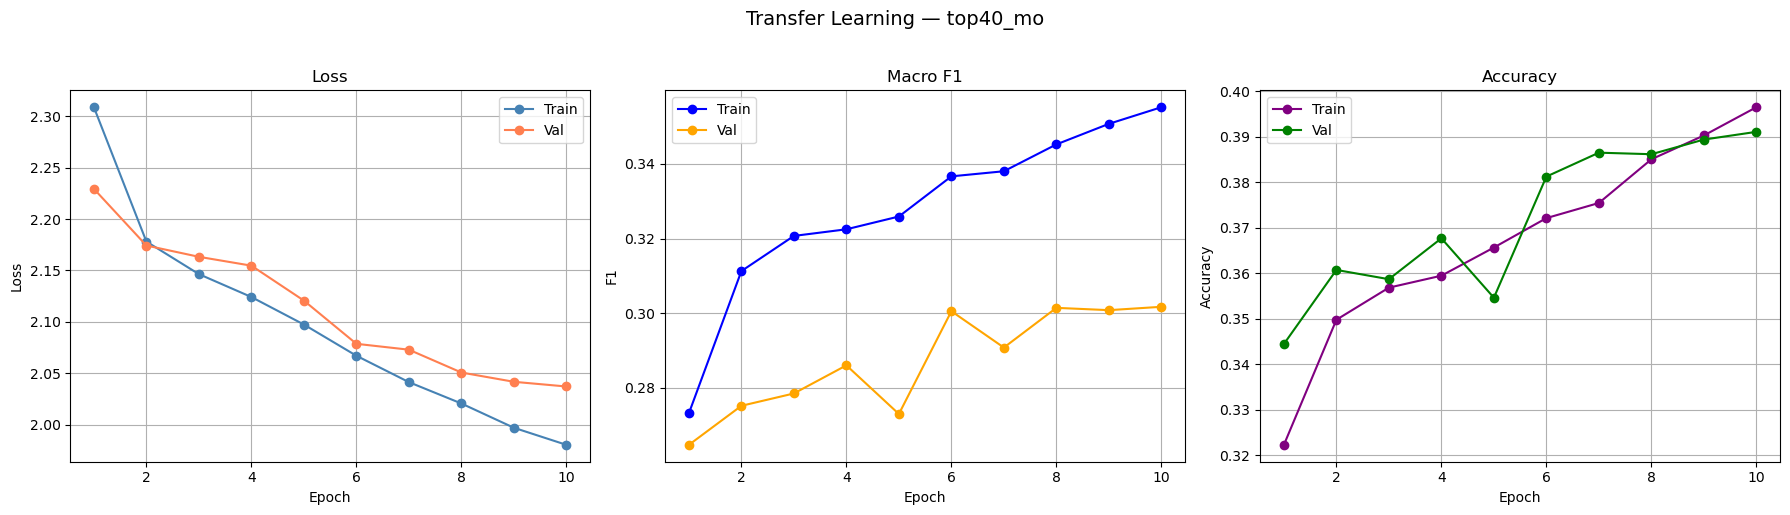


=== Rezultate Test — top40_mo ===
F1 Macro:  0.3122
Accuracy:  0.3963
                    precision    recall  f1-score   support

        Alina Radu       0.33      0.09      0.14        11
     Aliona Ciurca       0.49      0.32      0.39       150
 Ana-Maria Dolghii       0.40      0.29      0.33       122
    Anatolie Esanu       0.50      0.15      0.23        20
       Aneta Grosu       0.24      0.12      0.16        48
 Buzdugan Loredana       0.19      0.08      0.11        38
 Constantin Uzdris       0.25      0.02      0.04        81
     Cristian Sava       0.31      0.35      0.33       327
    Cristina Dulea       0.48      0.24      0.32       120
    Cristina Mirca       0.31      0.32      0.32       271
  Cristina Popescu       0.26      0.14      0.18       289
      Diana Gatcan       0.38      0.55      0.45       268
     Diana Severin       0.41      0.41      0.41       284
   Dorina Butnaras       0.35      0.09      0.14        69
Ecaterina Arvintii       0.4

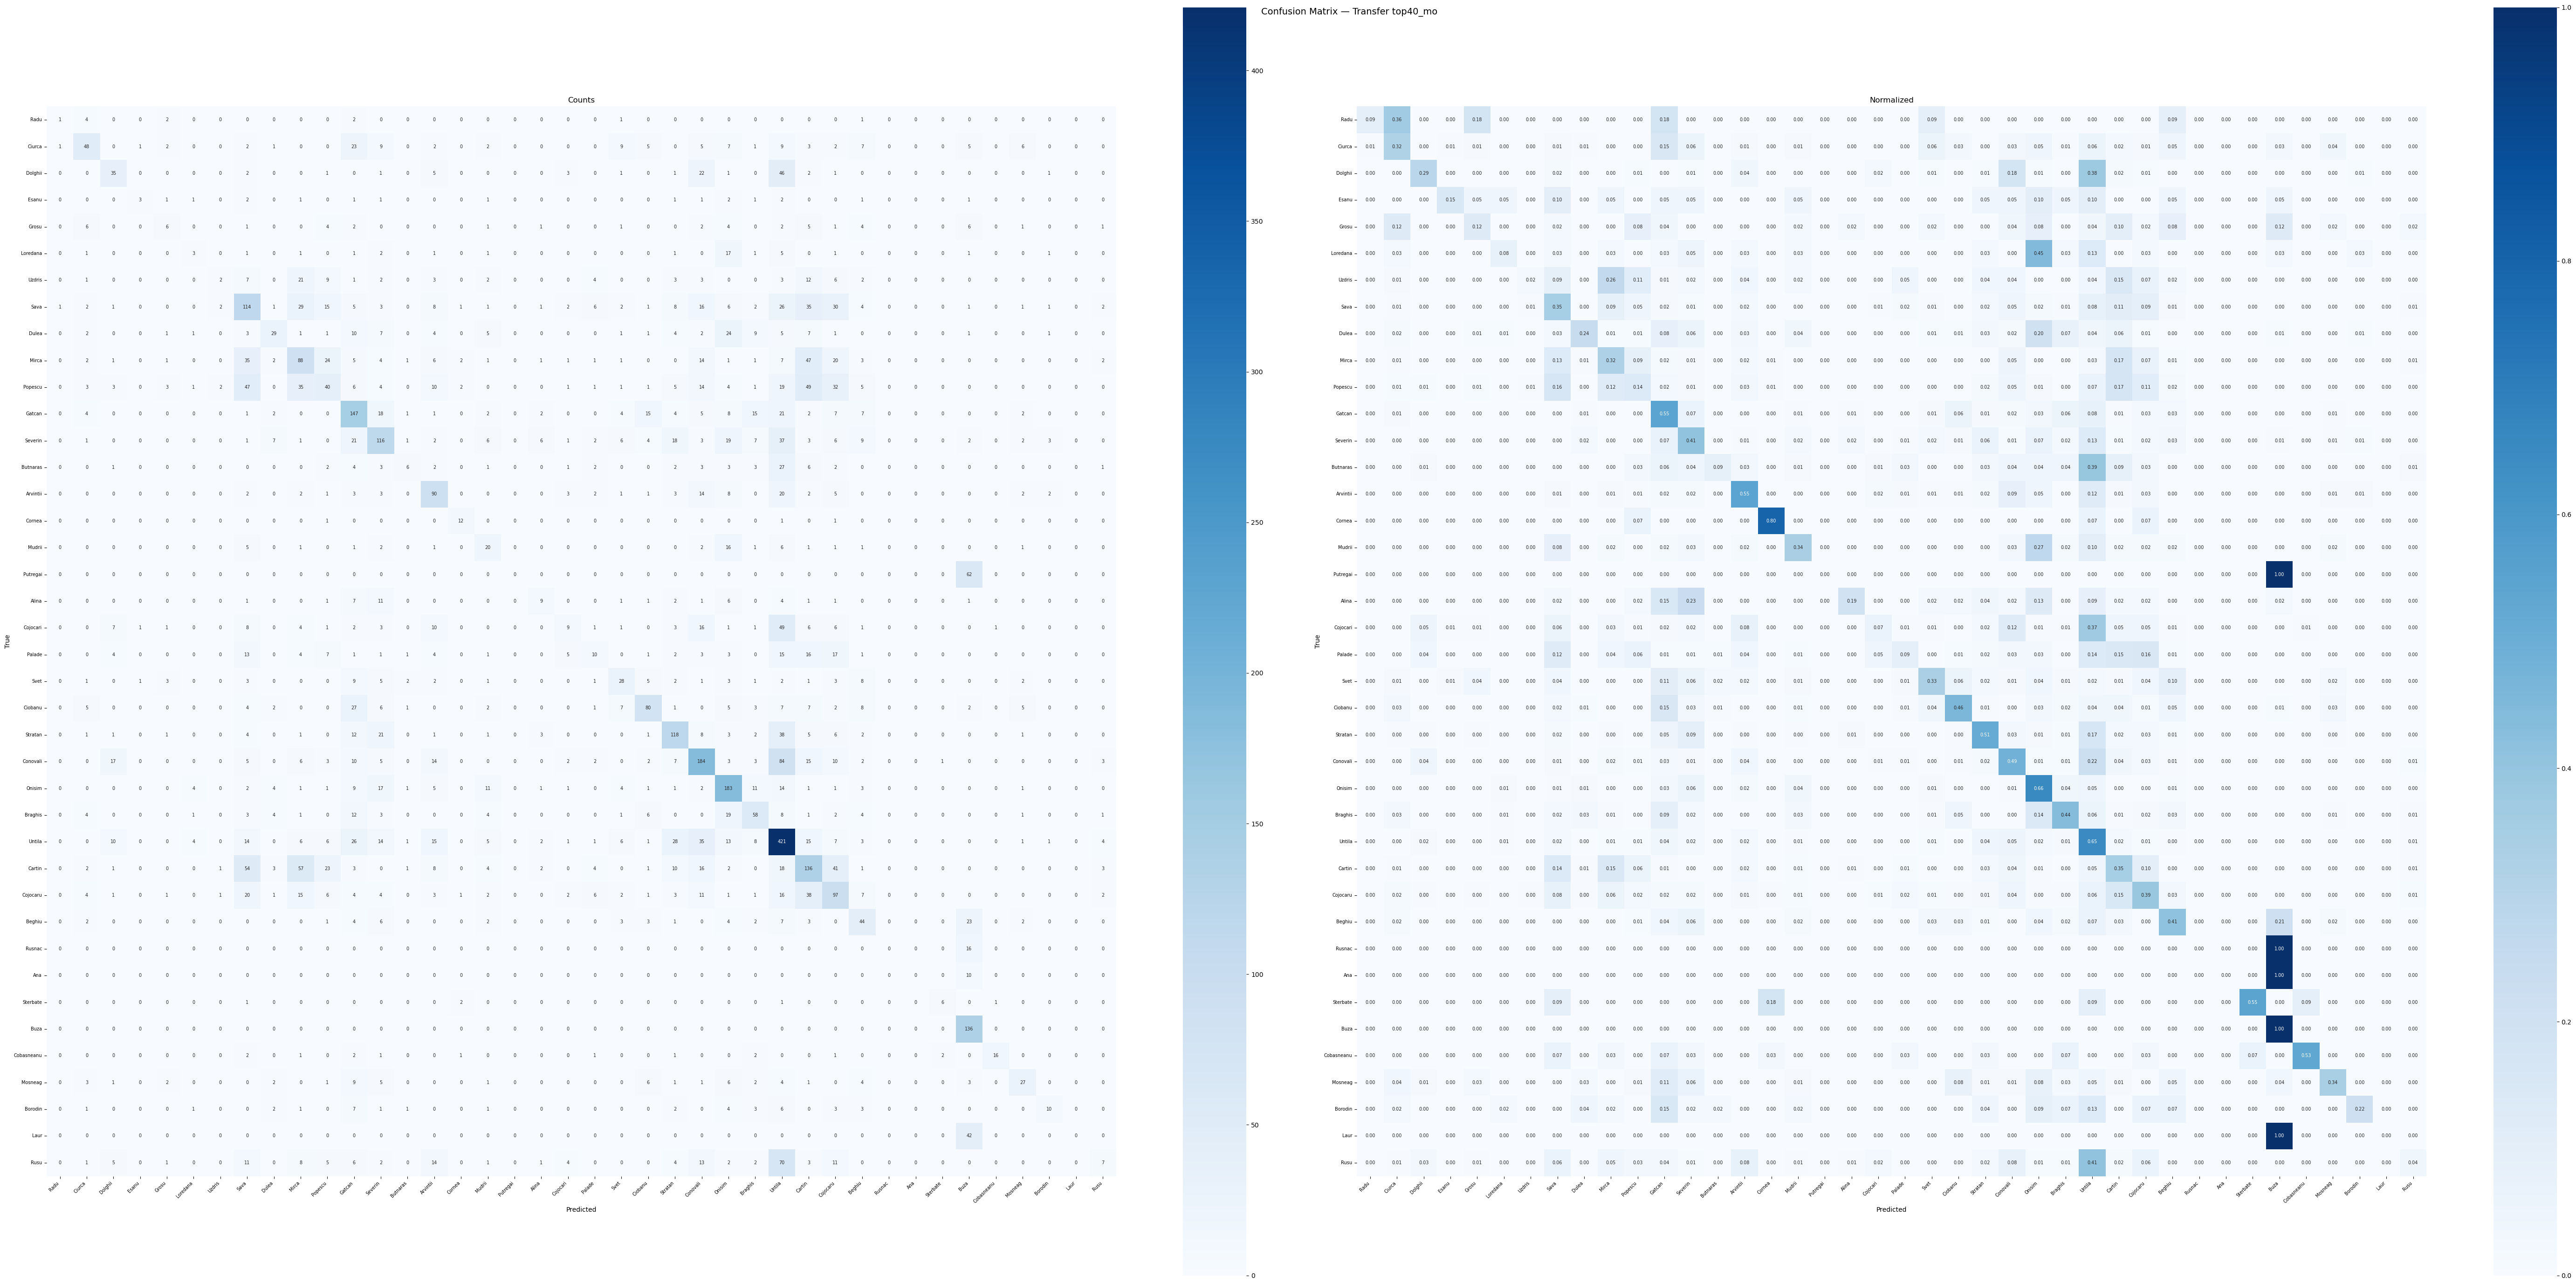


F1 Test: 0.3122
Best Val F1: 0.3017


In [27]:
result = run_transfer_experiment(
    train_df=train_df,
    val_df=val_df,
    test_df=test_df,
    pretrained_path='outputs_contrastive_2/top40_mo/best_triplet_top40_mo.pt',
    dataset_name='top40_mo',
    epochs=10,
    batch_size=16,
    lr=1e-3,
    seed=42
)

print(f"\nF1 Test: {result['f1_test']}")
print(f"Best Val F1: {result['best_val_f1']}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BERT frozen — parametri antrenabili: classifier only
Model incarcat: outputs_transfer/top40_mo/transfer_frozen_top40_mo.pt

=== Rezultate Test — top40_mo ===
F1 Macro:  0.3122
Accuracy:  0.3963
                    precision    recall  f1-score   support

        Alina Radu       0.33      0.09      0.14        11
     Aliona Ciurca       0.49      0.32      0.39       150
 Ana-Maria Dolghii       0.40      0.29      0.33       122
    Anatolie Esanu       0.50      0.15      0.23        20
       Aneta Grosu       0.24      0.12      0.16        48
 Buzdugan Loredana       0.19      0.08      0.11        38
 Constantin Uzdris       0.25      0.02      0.04        81
     Cristian Sava       0.31      0.35      0.33       327
    Cristina Dulea       0.48      0.24      0.32       120
    Cristina Mirca       0.31      0.32      0.32       271
  Cristina Popescu       0.26      0.14      0.18       289
      Diana Gatcan       0.38      0.55      0.45       268
     Diana Severin       

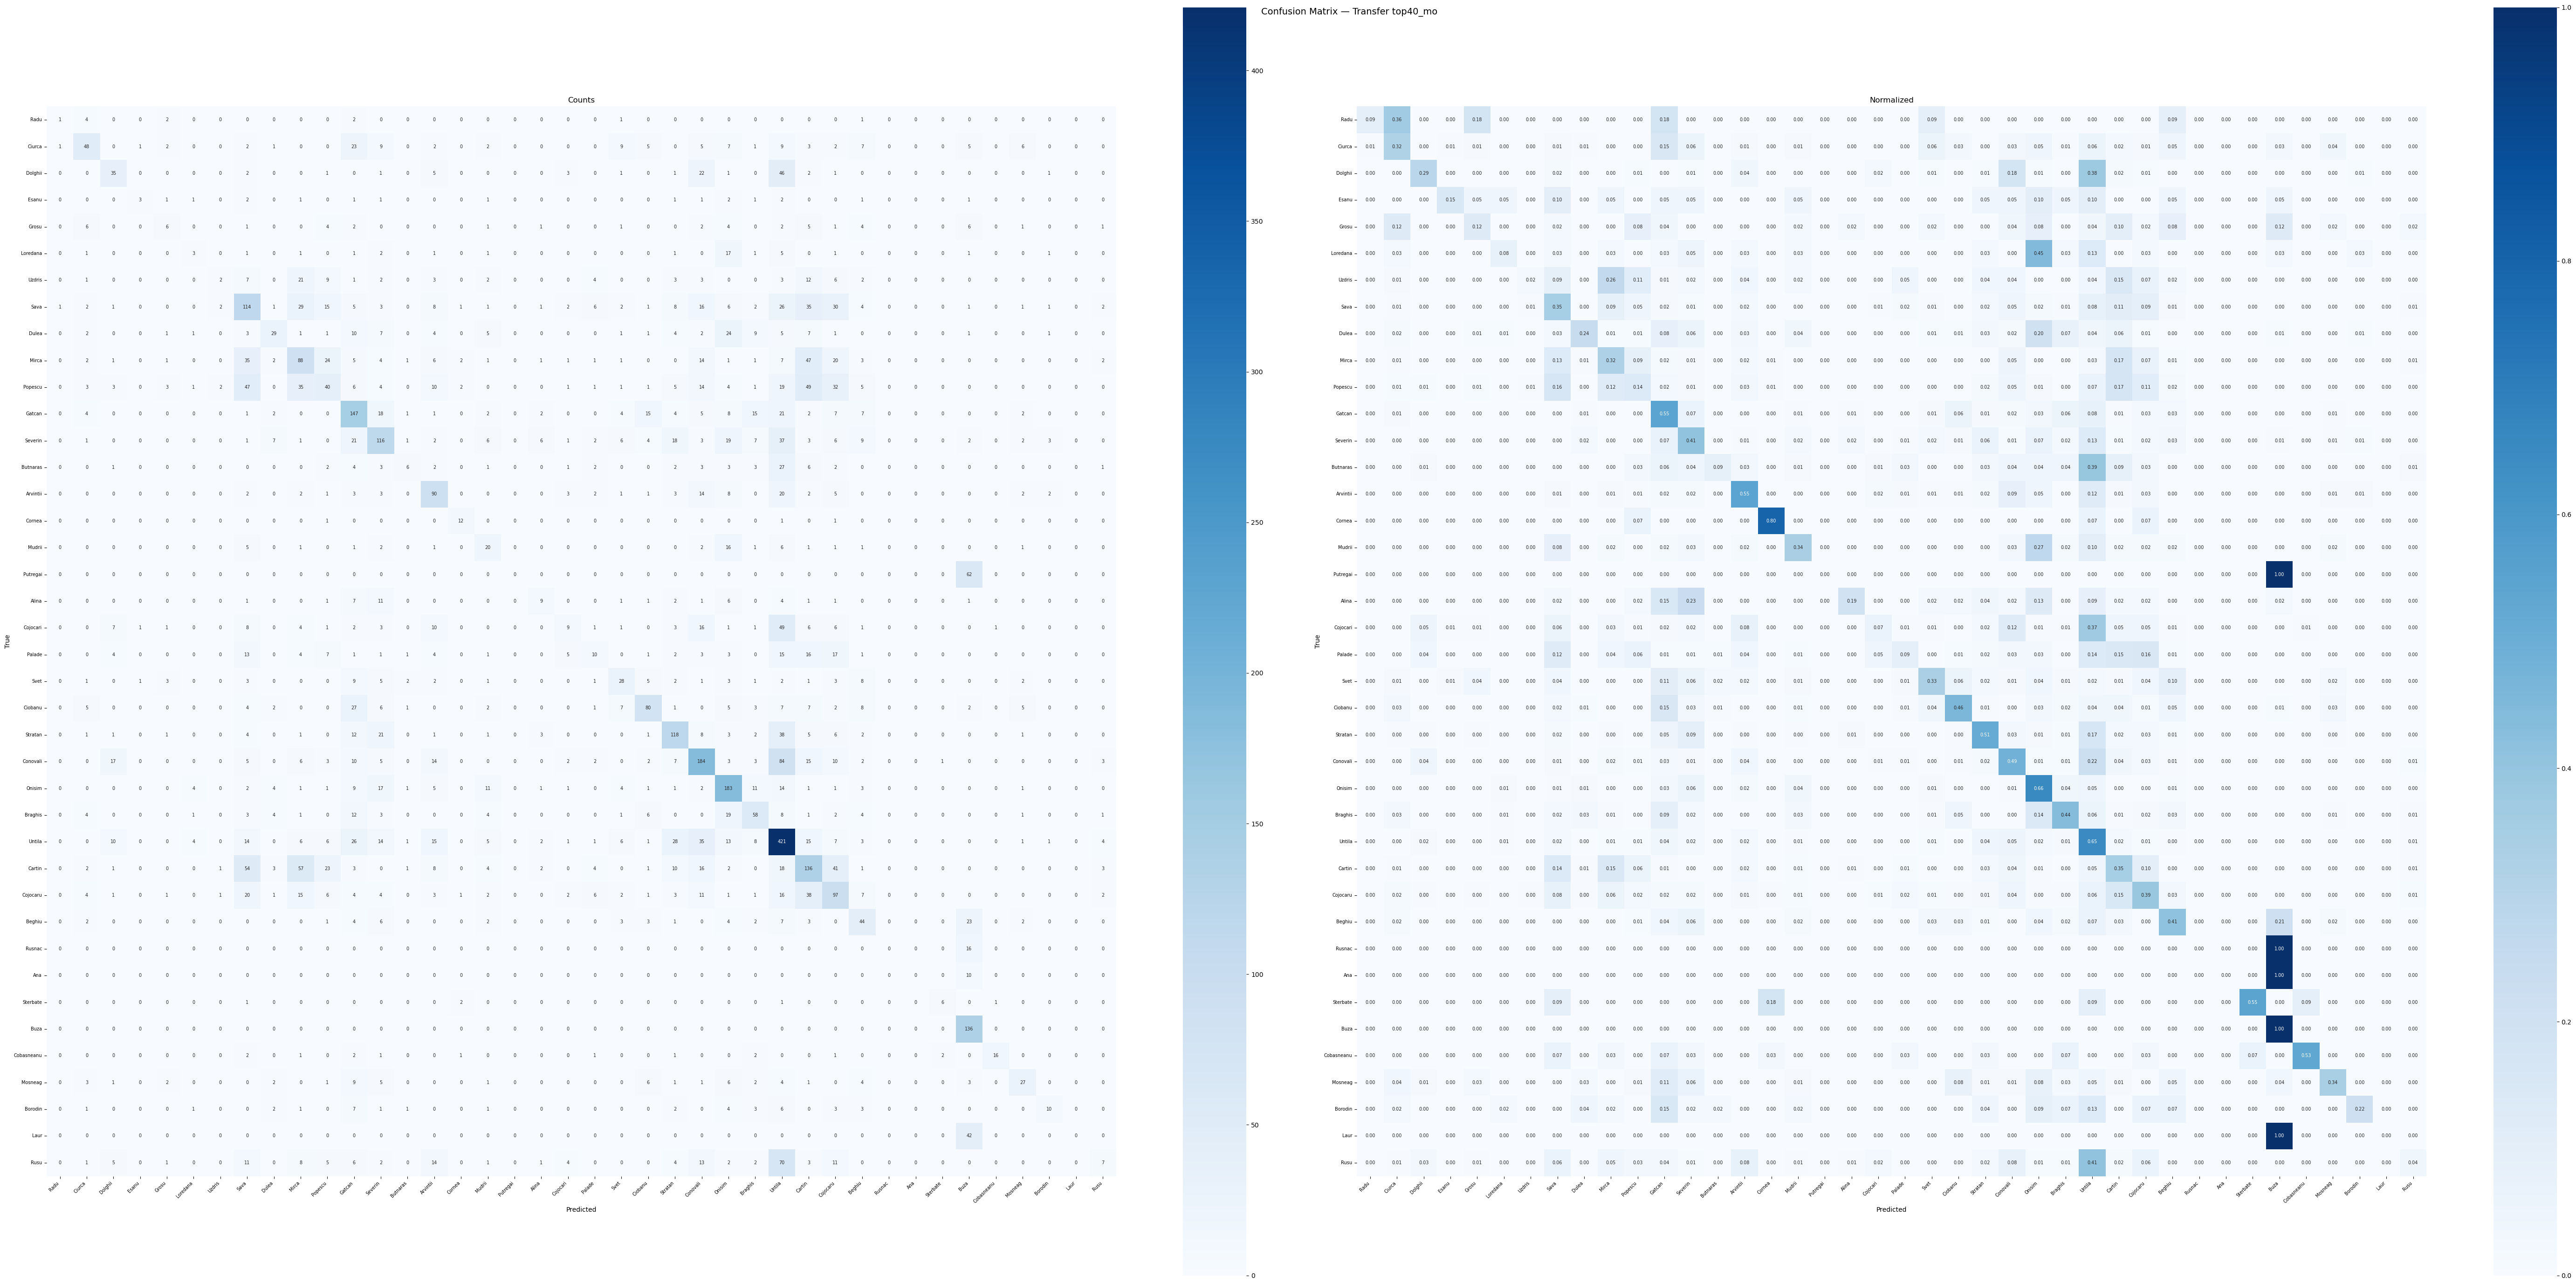

In [ ]:
preds, f1, acc = evaluate_transfer_from_checkpoint(
    model_path='outputs_transfer/top40_mo/transfer_frozen_top40_mo.pt',
    pretrained_path='outputs_contrastive_2/top40_mo/best_triplet_top40_mo.pt',
    train_df=train_df,
    test_df=test_df,
    dataset_name='top40_mo'
)
# 2 minute